# TP3 — Regulación de redes neuronales

**Redes Neuronales | 20 Newsgroups**

En base a las recomendaciones vistas durante las clases de regularización incluir como hiperparámetros posibles en el trabajo práctico de Clasificación de TNG los siguientes elementos:

* Regularización L1/L2, L1+L2
* Dropout
* BatchNormalization

Para cada caso tener en cuenta las recomendaciones de clase. Mirar valores absolutos de pesos. Tiempos de entrenamiento. Valores de Learning Rate. Ruido en las curvas de aprendizaje. Justificar con lo visto en clase los fenómenos observados.

# 1.Configuración inicial

Importamos las bibliotecas, fijamos la semilla aleatoria, elegimos CPU o GPU y preparamos las carpetas. La semilla favorece la reproducibilidad, aunque no garantiza resultados idénticos en todos los dispositivos.

In [1]:
!pip install -q optuna

In [2]:
from google.colab import drive
from pathlib import Path
import time
import json
import shutil

import re
import random
import numpy as np
import copy
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import optuna

import sqlite3

## 1.1Configuración global y Drive

In [3]:
# Montar Google Drive
drive.mount("/content/drive")

# Semilla y dispositivo
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Mounted at /content/drive
Usando dispositivo: cpu


In [4]:
# Carpeta principal del TP3
BASE_DIR = Path("/content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP3")

# Subcarpetas
RESULTS_DIR = BASE_DIR / "resultados"
MODELS_DIR = BASE_DIR / "modelos"
BACKUP_DIR = BASE_DIR / "backups"

for folder in [BASE_DIR, RESULTS_DIR, MODELS_DIR, BACKUP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Base de Optuna en el almacenamiento local de Colab
LOCAL_DB = Path("/content/optuna_tp3.db")
BACKUP_DB = BACKUP_DIR / "optuna_tp3.db"


print("Carpeta principal:", BASE_DIR)
print("Base de Optuna:", LOCAL_DB)
print("Backup:", BACKUP_DB)

print("Google Drive:", BASE_DIR.exists())
print("Carpeta resultados:", RESULTS_DIR.exists())
print("Carpeta modelos:", MODELS_DIR.exists())
print("Carpeta backups:", BACKUP_DIR.exists())

Carpeta principal: /content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP3
Base de Optuna: /content/optuna_tp3.db
Backup: /content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP3/backups/optuna_tp3.db
Google Drive: True
Carpeta resultados: True
Carpeta modelos: True
Carpeta backups: True


## 1.2 Recursos NLTK

In [5]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

# 2.Datos y representación de textos

Usamos **20 Newsgroups**, un conjunto de documentos etiquetados en 20 categorías. Conservamos la división original de entrenamiento y test, y separamos una parte del entrenamiento para validación. El test no se utiliza para seleccionar hiperparámetros.

Para convertir texto en números aplicamos tokenización, filtrado de palabras vacías y lematización, seguidos de TF-IDF. La vectorización se ajusta únicamente con entrenamiento y luego se aplica a validación: así evitamos introducir información de validación en el vocabulario o en las estadísticas IDF.

In [6]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)

# ----------------------------------

STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)


# Ajustar TF-IDF solo con entrenamiento; transformar otros conjuntos sin volver a ajustar.
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df
    )
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


### 2.1. Preprocesameinto - Configuración heredada del TP1

Se mantiene la configuración de preprocesamiento seleccionada en el TP1: eliminación de **stopwords**, **lematización**, n-gramas **(1, 2)**, un máximo de **10.000 características** y `min_df=5`.

Estos hiperparámetros se mantienen fijos para acotar el espacio de búsqueda y concentrar el TP2 en la arquitectura y el entrenamiento de la MLP. En cambio, se vuelven a explorar la tasa de aprendizaje (`lr`) y el tamaño de batch (`batch_size`).

El conjunto de validación se obtiene mediante una división estratificada, conservando aproximadamente la proporción de documentos de cada categoría.

In [7]:
# CONFIGURACIÓN FIJA Y DIVISIÓN
# Preprocesamiento fijo, recuperado del TP1

REMOVE_STOPWORDS = True
NORMALIZATION = "lemmatize"
NGRAM_RANGE = (1, 2)
MAX_FEATURES = 10000
MIN_DF = 5

# División fija de entrenamiento y validación
train_texts, val_texts, y_train, y_val = train_test_split(
    newsgroups_train.data,
    newsgroups_train.target,
    test_size=0.2,
    random_state=SEED,
    stratify=newsgroups_train.target
)

print("Documentos de entrenamiento:", len(train_texts))
print("Documentos de validación:", len(val_texts))


Documentos de entrenamiento: 9051
Documentos de validación: 2263


In [8]:
# Preprocesamiento de los textos
print("Preprocesando entrenamiento...")

train_proc = [
    preprocess_text(t, REMOVE_STOPWORDS, NORMALIZATION)
    for t in train_texts
]

print("Preprocesando validación...")

val_proc = [
    preprocess_text(t, REMOVE_STOPWORDS, NORMALIZATION)
    for t in val_texts
]

print("Preprocesamiento finalizado.")


Preprocesando entrenamiento...
Preprocesando validación...
Preprocesamiento finalizado.


In [9]:
# Vectorización

X_train, X_val, vectorizer = vectorize_data(
    train_proc,
    val_proc,
    ngram_range=NGRAM_RANGE,
    max_features=MAX_FEATURES,
    min_df=MIN_DF
)

print("Dimensión de entrenamiento:", X_train.shape)
print("Dimensión de validación:", X_val.shape)
print("Características utilizadas:", len(vectorizer.vocabulary_))


# Conversión a TensorDataset

train_dataset = to_tensor_dataset(X_train, y_train)
val_dataset = to_tensor_dataset(X_val, y_val)

INPUT_DIM = X_train.shape[1]

print("\n--Conversión a TensorDataset--")
print("Dimensión de entrada:", INPUT_DIM)
print("Cantidad de clases:", NUM_CLASSES)
print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))


Dimensión de entrenamiento: (9051, 10000)
Dimensión de validación: (2263, 10000)
Características utilizadas: 10000

--Conversión a TensorDataset--
Dimensión de entrada: 10000
Cantidad de clases: 20
Train dataset: 9051
Validation dataset: 2263


# 3.Definición del modelo MLP

Para el TP3 se utiliza como modelo base la MLP que obtuvo el mejor desempeño durante la optimización de hiperparámetros realizada en el TP2. La configuración seleccionada, recuperada directamente de la base de datos de Optuna, es la siguiente:

* Arquitectura: una capa oculta de 256 neuronas.
* Función de activación: Sigmoid.
* Optimizador: Adam.
* Batch size: 64.
* Learning rate: 0,00041875947.
* Parámetros de Adam: β₁ = 0,95 y β₂ = 0,999.
* Weight decay: 0.

El mejor modelo se selecciona según el **mayor accuracy de validación**, guardando los pesos correspondientes a esa época.

Se decidió desactivar el *early stopping* entrenar durante 50 épocas. Esto permite comparar la evolución completa de las curvas de aprendizaje y de los pesos entre las distintas técnicas de regularización, sin que una detención anticipada afecte el análisis.

In [10]:
# Recuperar el mejor modelo del TP2

TP2_DB = Path(
    "/content/drive/MyDrive/Facultad documentos/20266/2C/"
    "16.32 Redes neuronales/tp/TP2/backups/optuna_mlp.db"
)

if not TP2_DB.is_file():
    raise FileNotFoundError(f"No se encontró la base del TP2: {TP2_DB}")

storage_tp2 = f"sqlite:///{TP2_DB}"

# Recuperar el estudio de Adam
study = optuna.load_study(
    study_name="mlp_adam_50ep_es8",
    storage=storage_tp2
)

best = study.best_trial

# Recuperar los hiperparámetros
params = best.params

N_LAYERS = params["n_layers"]
ACTIVATION = params["activation"]
BATCH_SIZE = params["batch_size"]

LR = params["lr"]
BETA1 = params["beta1"]
BETA2 = params["beta2"]

# Recuperar las neuronas de cada capa
WIDTH_OPTIONS = [32, 64, 128, 256]

HIDDEN_LAYERS = [
    WIDTH_OPTIONS[params[f"width_idx_{i}"]]
    for i in range(1, N_LAYERS + 1)
]

# Regularización original del TP2
WEIGHT_DECAY_TP2 = params["weight_decay"]

# Mostrar configuración recuperada
resultados = {
    "Optimizador": "Adam",
    "Trial": best.number,
    "Accuracy validación (%)": best.value * 100,
    "Mejor época": best.user_attrs.get("best_epoch"),
    "Épocas ejecutadas": best.user_attrs.get("epochs_completed"),
    "Tiempo total (s)": best.user_attrs.get("total_time"),
    "Capas ocultas": N_LAYERS,
    "Neuronas por capa": HIDDEN_LAYERS,
    "Activación": ACTIVATION,
    "Parámetros entrenables": best.user_attrs.get("n_params"),
    "Batch size": BATCH_SIZE,
    "Learning rate": LR,
    "Weight decay TP2": WEIGHT_DECAY_TP2,
    "Beta 1": BETA1,
    "Beta 2": BETA2
}

display(pd.DataFrame.from_dict(
    resultados,
    orient="index",
    columns=["Valor"]
))

,Valor
Optimizador,Adam
Trial,4
Accuracy validación (%),74.016792
Mejor época,31
Épocas ejecutadas,50
Tiempo total (s),28.549227
Capas ocultas,1
Neuronas por capa,[256]
Activación,sigmoid
Parámetros entrenables,2565396


In [11]:
# Definición de la MLP
# clase MLP para construir la red neuronal a partir de los hiperparámetros seleccionados
# Permite configurar la cantidad de capas ocultas, el número de neuronas por capa y la función de activación,
# además de incorporar opcionalmente Dropout y Batch Normalization.

class MLP(nn.Module):
    def __init__(
        self,
        input_dim,
        num_classes,
        hidden_layers,
        activation,
        dropout=0.0,
        batch_norm=False
    ):
        super().__init__()

        activations = {
            "relu": nn.ReLU,
            "tanh": nn.Tanh,
            "sigmoid": nn.Sigmoid
        }

        if activation not in activations:
            raise ValueError("Activación no válida")

        if not 0 <= dropout < 1:
            raise ValueError("Dropout debe estar entre 0 y 1")

        layers = []
        in_features = input_dim

        for neurons in hidden_layers:

            layers.append(
                nn.Linear(
                    in_features,
                    neurons,
                    bias=not batch_norm
                )
            )

            if batch_norm:
                layers.append(nn.BatchNorm1d(neurons))

            layers.append(activations[activation]())

            if dropout > 0:
                layers.append(nn.Dropout(p=dropout))

            in_features = neurons

        layers.append(nn.Linear(in_features, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [12]:
# Análisis de pesos y MaxNorm

# la función registra cómo evolucionan los pesos durante el entrenamiento
def get_weight_metrics(model, epsilon=1e-3):

    weights = torch.cat([
        module.weight.detach().flatten()
        for module in model.modules()
        if isinstance(module, nn.Linear)
    ])

    abs_weights = weights.abs()

    return {
        "mean_abs_weight": abs_weights.mean().item(),
        "max_abs_weight": abs_weights.max().item(),
        "weight_l2_norm": torch.linalg.vector_norm(weights).item(),
        "fraction_near_zero": (
            (abs_weights < epsilon).float().mean().item()
        )
    }


# limitar la norma de los pesos de cada neurona
# incorporando opcionalmente la regularización MaxNorm durante el entrenamiento.
@torch.no_grad()
def apply_max_norm(model, max_norm):

    for module in model.modules():
        if isinstance(module, nn.Linear):

            # Cada fila representa los pesos de una neurona
            norms = torch.linalg.vector_norm(
                module.weight,
                dim=1,
                keepdim=True
            )

            scale = torch.clamp(
                max_norm / norms.clamp_min(1e-12),
                max=1.0
            )

            module.weight.mul_(scale)

In [13]:
# Entrenamiento de la MLP
# puedo incorporar regularización L1, L2 y MaxNorm de manera opcional
# Durante el entrenamiento, registra las métricas de desempeño, la evolución de los pesos, los tiempos por época y el learning rate
# Además, permite aplicar early stopping

def train_mlp_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs,
    run_name="baseline",
    l1_lambda=0.0,
    l2_lambda=0.0,
    max_norm=None,
    early_stopping_patience=None,
    min_delta=0.0,
    save_results=True,
    save_model=True,
    force_retrain=False
):

    # Verificar si ya se enrtenó
    results_path = RESULTS_DIR / f"{run_name}.csv"
    model_path = MODELS_DIR / f"{run_name}_best.pth"

    if not force_retrain and results_path.exists() and model_path.exists():

        checkpoint = torch.load(
            model_path,
            map_location=device,
            weights_only=True
        )

        # Verificar que los hiperparámetros coincidan
        same_config = (
            checkpoint.get("l1_lambda") == l1_lambda
            and checkpoint.get("l2_lambda") == l2_lambda
            and checkpoint.get("max_norm") == max_norm
        )

        if not same_config:
            raise ValueError(
                f"Ya existe un experimento llamado '{run_name}', "
                "pero sus parámetros de regularización son diferentes. "
                "Utilizá otro run_name para evitar sobrescribirlo."
            )

        # Recuperar el modelo
        model.load_state_dict(checkpoint["model_state_dict"])
        model.to(device)

        # Recuperar el historial
        history = pd.read_csv(results_path).to_dict("list")

        print(f"Experimento '{run_name}' recuperado.")
        print("No es necesario volver a entrenar.")
        print(f"Mejor época: {checkpoint['best_epoch']}")
        print(
            f"Mejor accuracy validación: "
            f"{checkpoint['best_val_acc']:.4f}"
        )

        return history



    model.to(device)
    criterion = nn.CrossEntropyLoss()

    history = {
        "epoch": [],
        "train_loss": [],
        "train_eval_loss": [],
        "val_loss": [],
        "train_acc": [],
        "train_eval_acc": [],
        "val_acc": [],
        "epoch_time": [],
        "lr": [],
        "mean_abs_weight": [],
        "max_abs_weight": [],
        "weight_l2_norm": [],
        "fraction_near_zero": []
    }

    best_val_acc = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None
    epochs_without_improvement = 0

    def evaluate(loader):
        model.eval()
        running_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for xb, yb in loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(xb)
                loss = criterion(logits, yb)

                running_loss += loss.item() * xb.size(0)
                correct += (
                    (logits.argmax(dim=1) == yb).sum().item()
                )
                total += xb.size(0)

        return running_loss / total, correct / total

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_total = time.perf_counter()

    for epoch in range(epochs):

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_epoch = time.perf_counter()

        # Entrenamiento
        model.train()

        running_loss, correct, total = 0.0, 0, 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)

            # Pérdida de clasificación
            ce_loss = criterion(logits, yb)

            # Penalizaciones sobre los pesos lineales
            weights = [
                module.weight
                for module in model.modules()
                if isinstance(module, nn.Linear)
            ]

            loss = ce_loss

            if l1_lambda > 0:
                l1_penalty = sum(
                    w.abs().sum() for w in weights
                )
                loss = loss + l1_lambda * l1_penalty

            if l2_lambda > 0:
                l2_penalty = sum(
                    w.pow(2).sum() for w in weights
                )
                loss = loss + l2_lambda * l2_penalty

            loss.backward()
            optimizer.step()

            # Restricción opcional de norma máxima
            if max_norm is not None:
                apply_max_norm(model, max_norm)

            # Registrar CE sin penalización
            running_loss += ce_loss.item() * xb.size(0)

            correct += (
                (logits.argmax(dim=1) == yb).sum().item()
            )
            total += xb.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # Evaluación
        train_eval_loss, train_eval_acc = evaluate(train_loader)
        val_loss, val_acc = evaluate(val_loader)

        if device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.perf_counter() - start_epoch

        # Pesos
        weight_metrics = get_weight_metrics(model)

        # Registro
        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["train_eval_loss"].append(train_eval_loss)
        history["val_loss"].append(val_loss)

        history["train_acc"].append(train_acc)
        history["train_eval_acc"].append(train_eval_acc)
        history["val_acc"].append(val_acc)

        history["epoch_time"].append(epoch_time)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        for key, value in weight_metrics.items():
            history[key].append(value)

        # Mejor modelo
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1

            if save_model:
                best_weights = copy.deepcopy(model.state_dict())

        # Early stopping
        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Resultados por época
        print(
            f"[{run_name}] "
            f"Epoch {epoch+1}/{epochs} | "
            f"train_acc={train_eval_acc:.4f} | "
            f"val_acc={val_acc:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"tiempo={epoch_time:.2f}s"
        )

        if (
            early_stopping_patience is not None
            and epochs_without_improvement >= early_stopping_patience
        ):
            print(f"Early stopping en época {epoch+1}")
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - start_total

    # Guardar
    if save_results:
        RESULTS_DIR.mkdir(parents=True, exist_ok=True)

        pd.DataFrame(history).to_csv(
            RESULTS_DIR / f"{run_name}.csv",
            index=False
        )

    if save_model and best_weights is not None:
        MODELS_DIR.mkdir(parents=True, exist_ok=True)

        torch.save(
            {
                "model_state_dict": best_weights,
                "best_epoch": best_epoch,
                "best_val_acc": best_val_acc,
                "best_val_loss": best_val_loss,
                "total_time": total_time,
                "l1_lambda": l1_lambda,
                "l2_lambda": l2_lambda,
                "max_norm": max_norm
            },
            MODELS_DIR / f"{run_name}_best.pth"
        )

    print(f"\nMejor época: {best_epoch}")
    print(f"Mejor accuracy validación: {best_val_acc:.4f}")
    print(f"Menor pérdida de validación: {best_val_loss:.4f}")
    print(f"Épocas ejecutadas: {len(history['epoch'])}/{epochs}")
    print(f"Tiempo total: {total_time:.2f}s")

    return history

# Modelo base

El modelo se entrena nuevamente desde cero, sin aplicar técnicas de regularización, durante un máximo de 50 épocas y sin early stopping, para obtener un punto de referencia. A partir de sus resultados se evaluará el efecto de incorporar L1, L2, Dropout y Batch Normalization, manteniendo inicialmente constantes los demás hiperparámetros.

En el modelo base, los pesos se inicializan aleatoriamente y se ajustan durante el entrenamiento mediante el optimizador Adam, que utiliza los gradientes de la función de pérdida *Cross-Entropy* para actualizarlos. Como no se aplica regularización, los pesos se modifican únicamente con el objetivo de reducir el error de clasificación, no incorpora ninguna penalización sobre la magnitud de los pesos.

In [14]:
# Baseline: modelo sin regularización

torch.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

model = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.0,
    batch_norm=False
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=256, out_features=20, bias=True)
  )
)


In [15]:
# Entrenamiento del baseline

history_baseline = train_mlp_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    epochs=50,
    run_name="baseline",
    l1_lambda=0.0,
    l2_lambda=0.0,
    max_norm=None,
    early_stopping_patience=None
)

Experimento 'baseline' recuperado.
No es necesario volver a entrenar.
Mejor época: 32
Mejor accuracy validación: 0.7380


In [16]:
# Resultados del modelo base

df_baseline = pd.DataFrame(history_baseline)

display(df_baseline.tail())

best_row = df_baseline.loc[df_baseline["val_acc"].idxmax()]

print(f"Mejor época: {int(best_row['epoch'])}")
print(f"Accuracy validación: {best_row['val_acc']:.4f}")
print(f"Loss validación: {best_row['val_loss']:.4f}")
print(f"Tiempo total: {df_baseline['epoch_time'].sum():.2f} s")

,epoch,train_loss,train_eval_loss,val_loss,train_acc,train_eval_acc,val_acc,epoch_time,lr,mean_abs_weight,max_abs_weight,weight_l2_norm,fraction_near_zero
45,46,0.189531,0.183423,0.893228,0.966302,0.967296,0.735307,6.068486,0.000419,0.203169,1.368219,393.304688,0.002669
46,47,0.182748,0.176324,0.894059,0.966302,0.967959,0.731330,5.825706,0.000419,0.204922,1.380758,396.600800,0.002658
47,48,0.175744,0.170835,0.896529,0.967296,0.968512,0.729563,6.668311,0.000419,0.206635,1.394928,399.827057,0.002595
48,49,0.170031,0.164309,0.895484,0.968401,0.969506,0.729563,5.691235,0.000419,0.208341,1.409320,403.041931,0.002590
49,50,0.163645,0.159840,0.897990,0.968291,0.969727,0.733981,6.901478,0.000419,0.210018,1.420714,406.201447,0.002620


Mejor época: 32
Accuracy validación: 0.7380
Loss validación: 0.9234
Tiempo total: 337.28 s


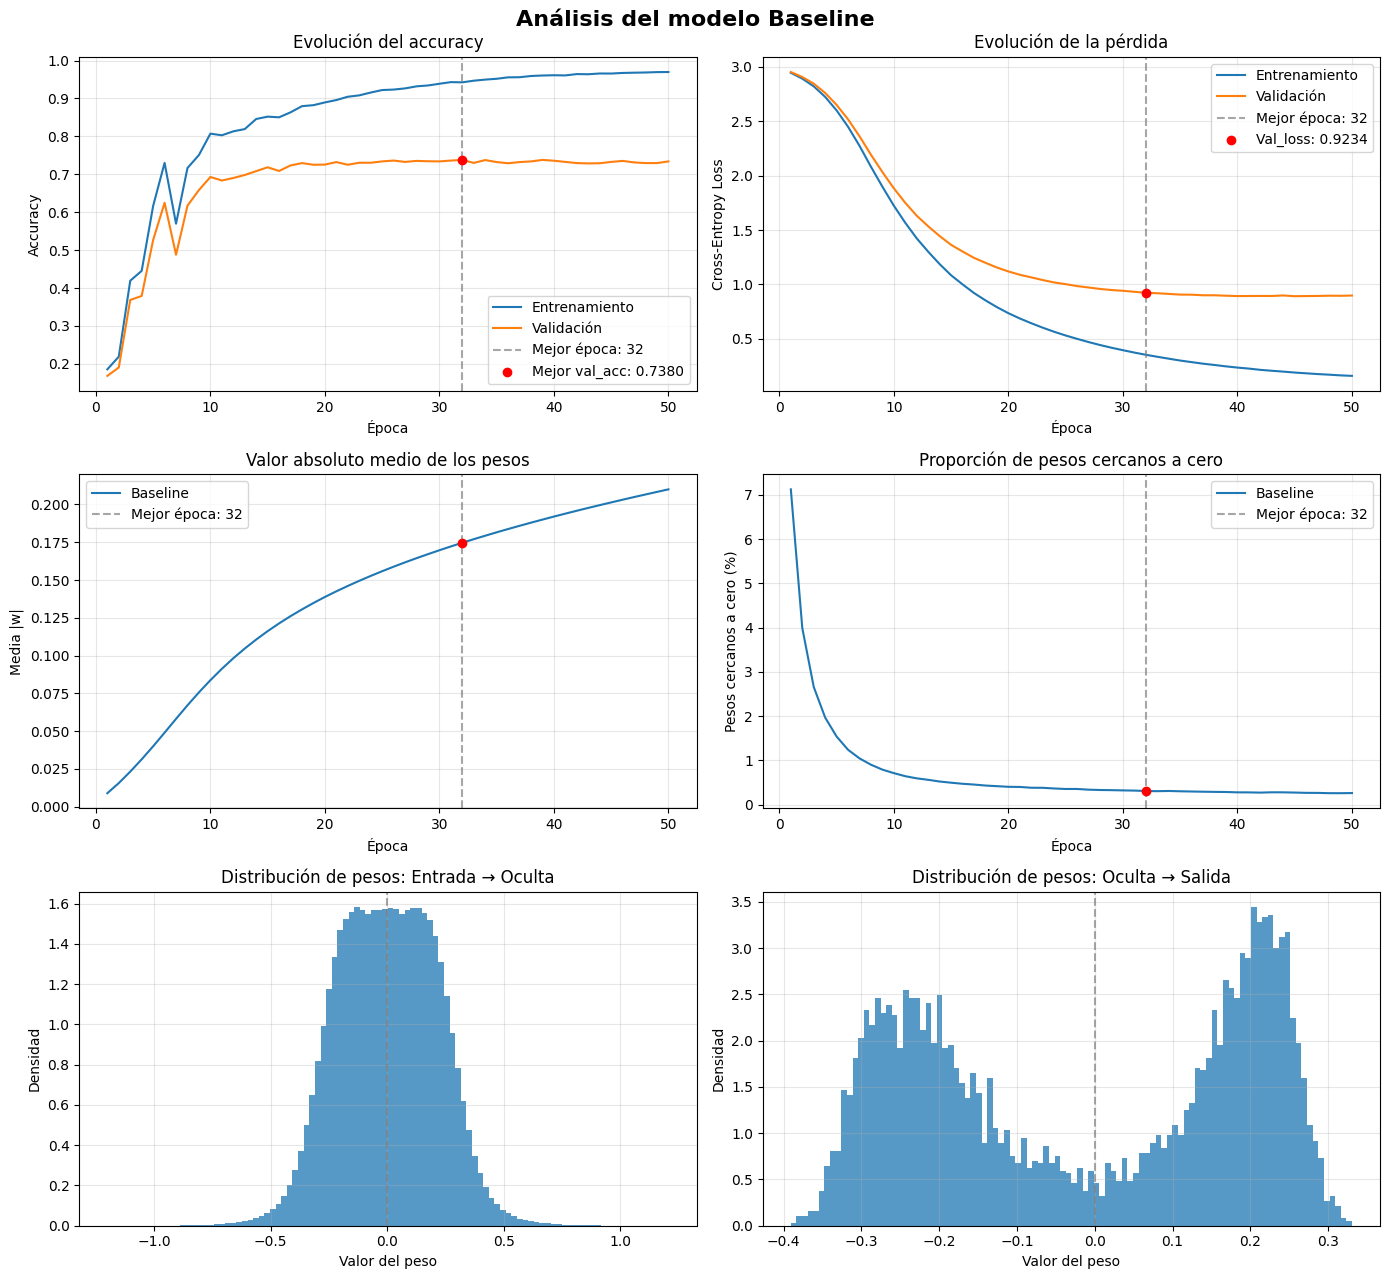


=== RESULTADOS DEL MEJOR MODELO BASELINE ===
Mejor época: 32
Accuracy de entrenamiento: 94.25%
Accuracy de validación: 73.80%
Pérdida de entrenamiento: 0.3535
Pérdida de validación: 0.9234

=== MÉTRICAS DE PESOS ===
Valor absoluto medio: 0.174681
Valor absoluto máximo: 1.206850
Pesos cercanos a cero: 0.31%


In [17]:
# Modelo base

# Historial
df = pd.read_csv(RESULTS_DIR / "baseline.csv")

best_idx = df["val_acc"].idxmax()
best_row = df.loc[best_idx]

best_epoch = int(best_row["epoch"])
best_acc = best_row["val_acc"]
best_loss = best_row["val_loss"]

checkpoint = torch.load(
    MODELS_DIR / "baseline_best.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

weights = [
    module.weight.detach().cpu().numpy().flatten()
    for module in model.modules()
    if isinstance(module, nn.Linear)
]



fig, axes = plt.subplots(3, 2, figsize=(14, 13))

fig.suptitle(
    "Análisis del modelo Baseline",
    fontsize=16,
    fontweight="bold"
)

# Accuracy
ax = axes[0, 0]

ax.plot(
    df["epoch"],
    df["train_eval_acc"],
    label="Entrenamiento"
)

ax.plot(
    df["epoch"],
    df["val_acc"],
    label="Validación"
)

ax.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label=f"Mejor época: {best_epoch}"
)

ax.scatter(
    best_epoch,
    best_acc,
    color="red",
    zorder=5,
    label=f"Mejor val_acc: {best_acc:.4f}"
)

ax.set_title("Evolución del accuracy")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(alpha=0.3)


# CROSS-ENTROPY LOSS
ax = axes[0, 1]

ax.plot(
    df["epoch"],
    df["train_eval_loss"],
    label="Entrenamiento"
)

ax.plot(
    df["epoch"],
    df["val_loss"],
    label="Validación"
)

ax.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label=f"Mejor época: {best_epoch}"
)

ax.scatter(
    best_epoch,
    best_loss,
    color="red",
    zorder=5,
    label=f"Val_loss: {best_loss:.4f}"
)

ax.set_title("Evolución de la pérdida")
ax.set_xlabel("Época")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend()
ax.grid(alpha=0.3)


# Valor absoluto medio de los pesos
ax = axes[1, 0]

ax.plot(
    df["epoch"],
    df["mean_abs_weight"],
    label="Baseline"
)

ax.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label=f"Mejor época: {best_epoch}"
)

ax.scatter(
    best_epoch,
    best_row["mean_abs_weight"],
    color="red",
    zorder=5
)

ax.set_title("Valor absoluto medio de los pesos")
ax.set_xlabel("Época")
ax.set_ylabel("Media |w|")
ax.legend()
ax.grid(alpha=0.3)


# Pesos cercanos a cero
ax = axes[1, 1]

ax.plot(
    df["epoch"],
    df["fraction_near_zero"] * 100,
    label="Baseline"
)

ax.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label=f"Mejor época: {best_epoch}"
)

ax.scatter(
    best_epoch,
    best_row["fraction_near_zero"] * 100,
    color="red",
    zorder=5
)

ax.set_title("Proporción de pesos cercanos a cero")
ax.set_xlabel("Época")
ax.set_ylabel("Pesos cercanos a cero (%)")
ax.legend()
ax.grid(alpha=0.3)


# Histogramas
layer_names = [
    "Entrada → Oculta",
    "Oculta → Salida"
]

for i, w in enumerate(weights):

    ax = axes[2, i]

    ax.hist(
        w,
        bins=100,
        density=True,
        alpha=0.75
    )

    ax.axvline(
        0,
        color="gray",
        linestyle="--",
        alpha=0.7
    )

    ax.set_title(f"Distribución de pesos: {layer_names[i]}")
    ax.set_xlabel("Valor del peso")
    ax.set_ylabel("Densidad")
    ax.grid(alpha=0.3)


plt.tight_layout()
plt.show()


print("\n=== RESULTADOS DEL MEJOR MODELO BASELINE ===")

print(f"Mejor época: {best_epoch}")

print(f"Accuracy de entrenamiento: {best_row['train_eval_acc']:.2%}")
print(f"Accuracy de validación: {best_acc:.2%}")

print(f"Pérdida de entrenamiento: {best_row['train_eval_loss']:.4f}")
print(f"Pérdida de validación: {best_loss:.4f}")

print()
print("=== MÉTRICAS DE PESOS ===")

print(f"Valor absoluto medio: {best_row['mean_abs_weight']:.6f}")
print(f"Valor absoluto máximo: {best_row['max_abs_weight']:.6f}")
print(f"Pesos cercanos a cero: {best_row['fraction_near_zero']:.2%}")

En esta etapa, el objetivo principal es analizar cómo evolucionan los pesos durante el entrenamiento. Por este motivo, el modelo se entrena durante 50 épocas sin aplicar *early stopping* ni un criterio de paciencia que detenga anticipadamente el entrenamiento.

El mejor modelo se selecciona según el mayor accuracy de validación, alcanzando un 73,80 % en la época 32, con una pérdida de validación de 0,9234.

En las curvas se observa que el accuracy de entrenamiento continúa aumentando, mientras que el de validación tiende a estabilizarse. Esta separación evidencia la presencia de sobreajuste, ya que el modelo sigue mejorando su desempeño sobre los datos de entrenamiento sin obtener mejoras equivalentes en validación.

En el modelo base, los pesos pueden aumentar a disminuir libremente. En el gráfico del valor absoluto medio se observa que la magnitud promedio de los pesos crece progresivamente durante el entrenamiento. En la mejor época, el valor absoluto máximo de los pesos es de 1,207.

El modelo base tampoco incorpora un término que favorezca valores chicos de pesos, por lo que la concentración cerca de cero esperamos que sea más baja que en modelos con regularización. En es caso, el 0,31% de los pesos se encontraba dentro del intervalo considerado cercano a cero en la mejor época. Se concideran pesos cercanos a cero los que cumplen: |w| < 0,001.

Con respecto a los histogramas, los pesos entre la capa de entrada y la capa oculta presentan una distribución aproximadamente simétrica y centrada alrededor de cero. En cambio, los pesos entre la capa oculta y la capa de salida muestran una distribución bimodal, con concentraciones de valores positivos y negativos. Más adelante analizaremos cómo cambian estas distribuciones al incorporar regularización.

# Regularización L1

La regularización **L1** incorpora a la función de pérdida una penalización proporcional a la suma de los valores absolutos de los pesos:

$$
\mathcal{L}_{\text{total}} = \mathcal{L}_{CE} + \lambda_1 \sum_{i=1}^{N} |w_i|
$$

Donde $\mathcal{L}_{CE}$ es la pérdida *Cross-Entropy*, $w_i$ representa cada peso de la red y $\lambda_1$ controla la intensidad de la regularización.

Esta penalización favorece que los pesos disminuyan su magnitud y que algunos se acerquen a cero, reduciendo la influencia de ciertas conexiones de la red.

En este experimento se evalúan dos coeficientes de regularización, $\lambda_1=10^{-7}$ y $\lambda_1=10^{-6}$, manteniendo la misma arquitectura y los hiperparámetros del modelo base. El objetivo es analizar cómo influye la intensidad de la penalización sobre la distribución de los pesos y el desempeño del modelo.

In [18]:
# Experimento 1: Regularización L1

L1_LAMBDA = 1e-7


torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


model_l1 = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.0,
    batch_norm=False
).to(device)

optimizer_l1 = torch.optim.Adam(
    model_l1.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)

history_l1 = train_mlp_model(
    model=model_l1,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_l1,
    epochs=50,
    run_name="l1_1e-7",
    l1_lambda=L1_LAMBDA,
    l2_lambda=0.0,
    max_norm=None,
    early_stopping_patience=None
)

Experimento 'l1_1e-7' recuperado.
No es necesario volver a entrenar.
Mejor época: 32
Mejor accuracy validación: 0.7371


In [19]:
# Experimento L1 con mayor regularización
L1_LAMBDA = 1e-6

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_l1_6 = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.0,
    batch_norm=False
).to(device)

optimizer_l1_6 = torch.optim.Adam(
    model_l1_6.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)

history_l1_6 = train_mlp_model(
    model=model_l1_6,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_l1_6,
    epochs=50,
    run_name="l1_1e-6",
    l1_lambda=L1_LAMBDA,
    l2_lambda=0.0,
    early_stopping_patience=None
)

Experimento 'l1_1e-6' recuperado.
No es necesario volver a entrenar.
Mejor época: 40
Mejor accuracy validación: 0.7366


In [20]:
df_base = pd.DataFrame(history_baseline)
df_l1 = pd.DataFrame(history_l1)
df_l1_6 = pd.DataFrame(history_l1_6)

experiments = {
    "Baseline": df_base,
    "L1 (1e-7)": df_l1,
    "L1 (1e-6)": df_l1_6
}

metrics = {
    "epoch": "Mejor época",
    "val_acc": "Accuracy validación",
    "val_loss": "Pérdida validación",
    "mean_abs_weight": "Valor absoluto medio",
    "max_abs_weight": "Valor absoluto máximo",
    "fraction_near_zero": "Pesos cercanos a cero"
}

results = {}

for name, df in experiments.items():
    best = df.loc[df["val_acc"].idxmax()]

    results[name] = {
        "Mejor época": f"{int(best['epoch'])}",
        "Accuracy validación": f"{best['val_acc']:.2%}",
        "Pérdida validación": f"{best['val_loss']:.4f}",
        "Valor absoluto medio": f"{best['mean_abs_weight']:.4f}",
        "Valor absoluto máximo": f"{best['max_abs_weight']:.4f}",
        "Pesos cercanos a cero": f"{best['fraction_near_zero']:.2%}"
    }

comparison_l1 = pd.DataFrame(results)

print("=== COMPARACIÓN DE REGULARIZACIÓN L1 ===")
display(comparison_l1)

=== COMPARACIÓN DE REGULARIZACIÓN L1 ===


,Baseline,L1 (1e-7),L1 (1e-6)
Mejor época,32,32,40
Accuracy validación,73.80%,73.71%,73.66%
Pérdida validación,0.9234,0.9313,0.9548
Valor absoluto medio,0.1747,0.1558,0.0888
Valor absoluto máximo,1.2069,1.2128,1.4205
Pesos cercanos a cero,0.31%,3.36%,28.00%


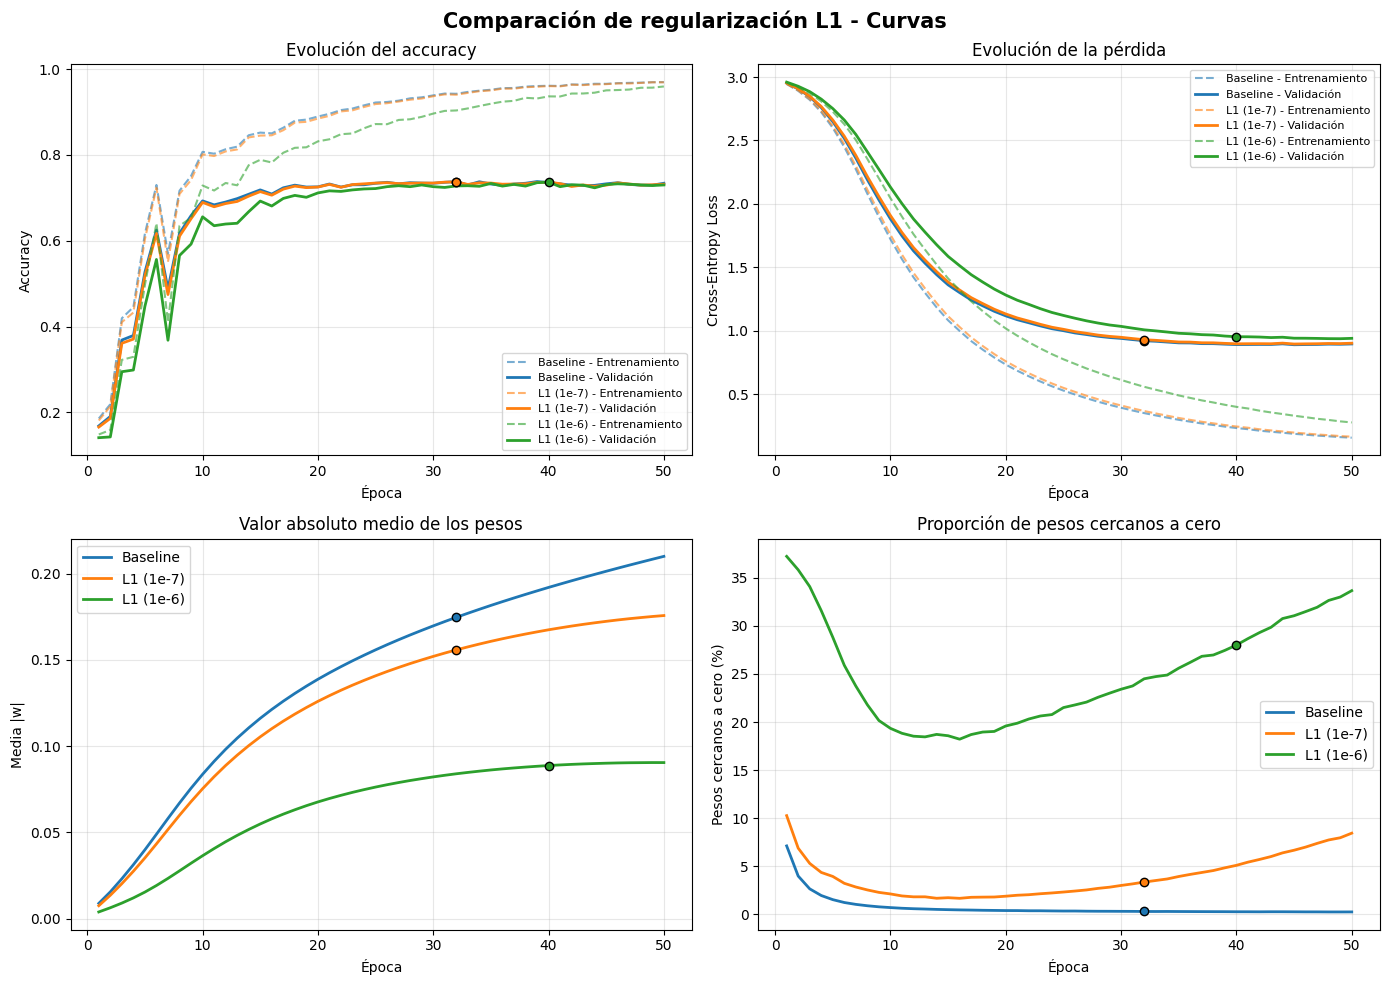

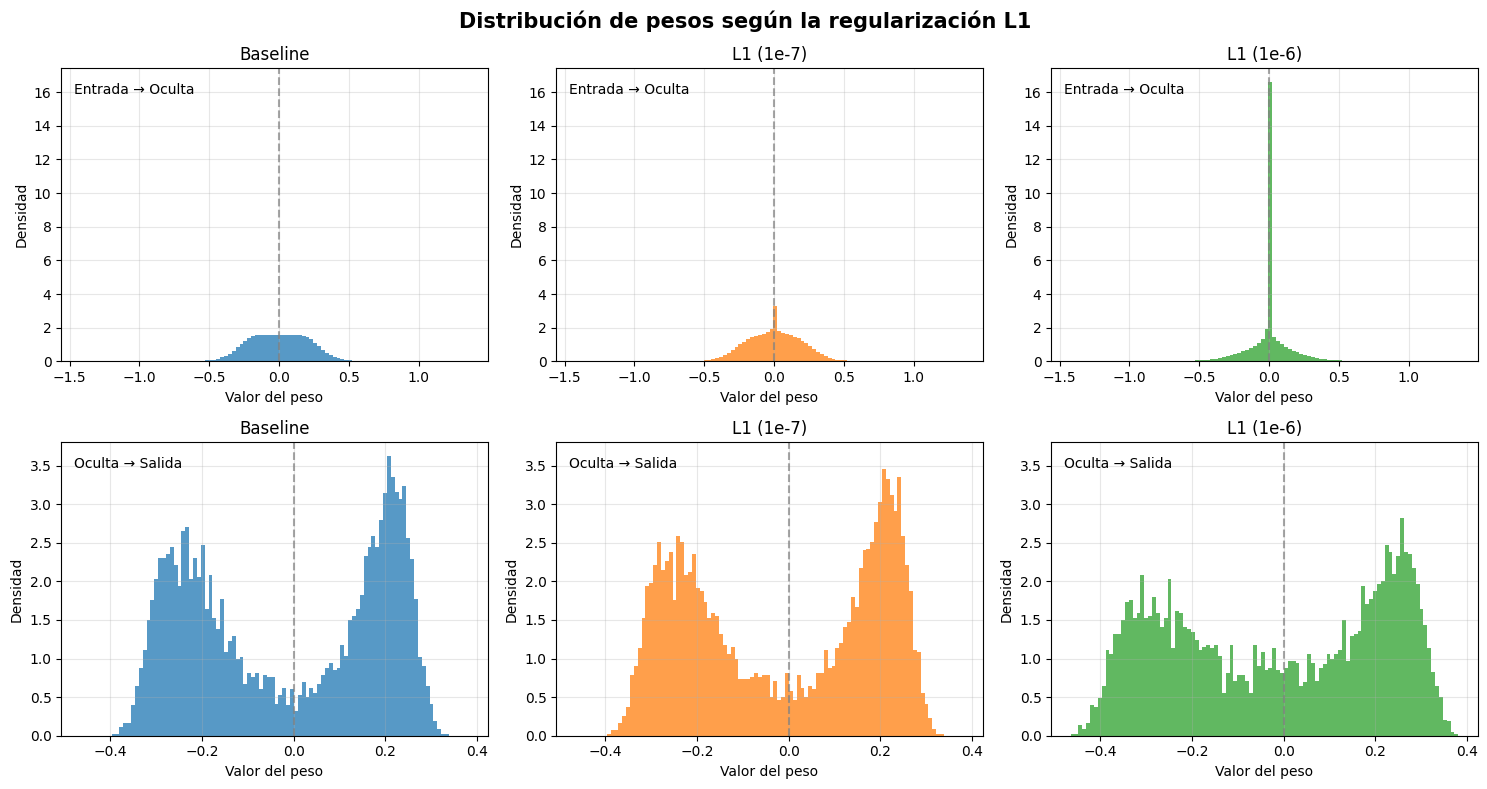



=== COMPARACIÓN DE REGULARIZACIÓN L1 ===


,Baseline,L1 (1e-7),L1 (1e-6)
Mejor época,32,32,40
Accuracy validación,73.80%,73.71%,73.66%
Pérdida validación,0.9234,0.9313,0.9548
Valor absoluto medio,0.1747,0.1558,0.0888
Valor absoluto máximo,1.2069,1.2128,1.4205
Pesos cercanos a cero,0.31%,3.36%,28.00%


In [21]:
# Comparación modelo base, L1 (1e-7) y L1 (1e-6)


# Historiales
experiments = {
    "Baseline": pd.read_csv(RESULTS_DIR / "baseline.csv"),
    "L1 (1e-7)": pd.read_csv(RESULTS_DIR / "l1_1e-7.csv"),
    "L1 (1e-6)": pd.read_csv(RESULTS_DIR / "l1_1e-6.csv")
}

colors = {
    "Baseline": "tab:blue",
    "L1 (1e-7)": "tab:orange",
    "L1 (1e-6)": "tab:green"
}

best_rows = {
    name: df.loc[df["val_acc"].idxmax()]
    for name, df in experiments.items()
}


# Curvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Accuracy
ax = axes[0, 0]

for name, df in experiments.items():
    color = colors[name]
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["train_eval_acc"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )

    ax.plot(
        df["epoch"], df["val_acc"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

    ax.scatter(
        best["epoch"], best["val_acc"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución del accuracy")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


# Cross-Entropy Loss
ax = axes[0, 1]

for name, df in experiments.items():
    color = colors[name]
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["train_eval_loss"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )

    ax.plot(
        df["epoch"], df["val_loss"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

    ax.scatter(
        best["epoch"], best["val_loss"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución de la pérdida")
ax.set_xlabel("Época")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


# Valor absoluto medio de los pesos
ax = axes[1, 0]

for name, df in experiments.items():
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["mean_abs_weight"],
        color=colors[name], linewidth=2, label=name
    )

    ax.scatter(
        best["epoch"], best["mean_abs_weight"],
        color=colors[name], edgecolor="black", zorder=5
    )

ax.set_title("Valor absoluto medio de los pesos")
ax.set_xlabel("Época")
ax.set_ylabel("Media |w|")
ax.legend()
ax.grid(alpha=0.3)


# Proporción de pesos cercanos a cero
ax = axes[1, 1]

for name, df in experiments.items():
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["fraction_near_zero"] * 100,
        color=colors[name], linewidth=2, label=name
    )

    ax.scatter(
        best["epoch"], best["fraction_near_zero"] * 100,
        color=colors[name], edgecolor="black", zorder=5
    )

ax.set_title("Proporción de pesos cercanos a cero")
ax.set_xlabel("Época")
ax.set_ylabel("Pesos cercanos a cero (%)")
ax.legend()
ax.grid(alpha=0.3)

fig.suptitle(
    "Comparación de regularización L1 - Curvas",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()
plt.show()


# Histogramas
checkpoints = {
    "Baseline": "baseline_best.pth",
    "L1 (1e-7)": "l1_1e-7_best.pth",
    "L1 (1e-6)": "l1_1e-6_best.pth"
}

weights_models = {}

for name, filename in checkpoints.items():

    checkpoint = torch.load(
        MODELS_DIR / filename,
        map_location=device,
        weights_only=True
    )

    model_temp = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=0.0,
        batch_norm=False
    ).to(device)

    model_temp.load_state_dict(checkpoint["model_state_dict"])

    weights_models[name] = [
        module.weight.detach().cpu().numpy().flatten()
        for module in model_temp.modules()
        if isinstance(module, nn.Linear)
    ]


fig, axes = plt.subplots(2, 3, figsize=(15, 8))

layer_names = [
    "Entrada → Oculta",
    "Oculta → Salida"
]

for layer_idx in range(2):

    # Mismos intervalos para los tres modelos de cada capa
    all_weights = np.concatenate([
        weights_models[name][layer_idx]
        for name in checkpoints
    ])

    bins = np.linspace(
        all_weights.min(),
        all_weights.max(),
        101
    )

    for col, name in enumerate(checkpoints):

        w = weights_models[name][layer_idx]
        ax = axes[layer_idx, col]

        ax.hist(
            w,
            bins=bins,
            density=True,
            color=colors[name],
            alpha=0.75
        )

        ax.axvline(
            0,
            color="gray",
            linestyle="--",
            alpha=0.7
        )

        ax.set_title(name)
        ax.set_xlabel("Valor del peso")
        ax.set_ylabel("Densidad")
        ax.grid(alpha=0.3)

        ax.text(
            0.03, 0.95,
            layer_names[layer_idx],
            transform=ax.transAxes,
            va="top",
            fontsize=10
        )

    # Misma escala vertical por fila para facilitar la comparación
    ymax = max(axes[layer_idx, col].get_ylim()[1] for col in range(3))

    for col in range(3):
        axes[layer_idx, col].set_ylim(0, ymax)

fig.suptitle(
    "Distribución de pesos según la regularización L1",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\n")

print("=== COMPARACIÓN DE REGULARIZACIÓN L1 ===")
display(comparison_l1)

- Curvas accuracy y pérdida

Las tres configuraciones presentan un comportamiento general similar al del modelo base, lo cual es esperable porque mantienen la misma arquitectura, el mismo optimizador y los mismos hiperparámetros de entrenamiento.

Sin embargo, el modelo con L1 $\lambda_1=10^{-6}$ presenta una evolución más lenta: el accuracy de entrenamiento aumenta más gradualmente y la pérdida disminuye a un ritmo menor. Esto puede explicarse por la mayor penalización aplicada sobre los pesos, que limita su ajuste durante el entrenamiento.

En validación, las diferencias son menores. Aunque el modelo con mayor regularización comienza con un accuracy más bajo y una menor pérdida, con el paso de la épocas llegan a valores similares (ocurre más rápido que en entrenamiento).

- Pesos

En los gráficos se observa que ambos modelos con regularización L1 presentan pesos de menor magnitud promedio que el baseline, siendo este efecto más pronunciado para $\lambda_1=10^{-6}$ . Aunque el valor absoluto medio de los pesos aumenta durante el entrenamiento en los tres modelos, la regularización L1 limita su crecimiento.

Por otro lado, la proporción de pesos cercanos a cero disminuye durante las primeras épocas, pero luego comienza a aumentar en los modelos regularizados. Este comportamiento es especialmente notable para $\lambda_1=10^{-6}$, que alcanza un 28,00 % de pesos cercanos a cero en su mejor época, frente al 3,36 % de L1 $\lambda_1=10^{-7}$ y el 0,31 % del baseline.

Estos resultados muestran que una mayor penalización L1 favorece una mayor concentración de pesos alrededor de cero y reduce su magnitud promedio.

- Histogramas

En los histogramas de los pesos entre la capa de entrada y la capa oculta se observa que la regularización L1 favorece la concentración de valores alrededor de cero. Para $\lambda_1=10^{-7}$ aparece un pico en cero que no estaba presente en el baseline, mientras que para $\lambda_1=10^{-6}$ este pico se vuelve mucho más pronunciado, evidenciando el efecto de una mayor penalización (pesos cercanos a cero, alcanza el 28 % para $\lambda_1=10^{-6}$.

En los pesos entre la capa oculta y la capa de salida se mantiene una distribución bimodal, con concentraciones de valores positivos y negativos. Para $\lambda_1=10^{-7}$, la distribución sigue siendo similar a la del baseline, aunque se observa una ligera mayor densidad alrededor de cero. En cambio, para $\lambda_1=10^{-6}$, la densidad en la región central aumenta y los dos picos se vuelven menos pronunciados.

Con la introducción de L1 vemos una reducción de la magnitud de los pesos, mientras que el *accuracy* de validación se mantiene prácticamente constante respecto del baseline.




# Regularización L2

La regularización **L2** incorpora a la función de pérdida una penalización proporcional a la suma de los cuadrados de los pesos:

$$
\mathcal{L}_{\text{total}} = \mathcal{L}_{CE} + \lambda_2 \sum_{i=1}^{N} w_i^2
$$

Esta penalización favorece la reducción de la magnitud de los pesos, especialmente de aquellos con valores elevados. A diferencia de L1, no promueve directamente que los pesos se vuelvan exactamente cero.

En este experimento se evalúan dos coeficientes de regularización, $\lambda_2=10^{-6}$ y $\lambda_2=10^{-5}$. El segundo representa una penalización diez veces mayor, lo que permite analizar cómo influye la intensidad de la regularización sobre la magnitud y distribución de los pesos y el desempeño del modelo.

En ambos casos se mantienen la misma arquitectura y los hiperparámetros de entrenamiento del modelo base.


In [22]:
# Experimento L2
L2_LAMBDA = 1e-6

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_l2 = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.0,
    batch_norm=False
).to(device)

optimizer_l2 = torch.optim.Adam(
    model_l2.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)

history_l2 = train_mlp_model(
    model=model_l2,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_l2,
    epochs=50,
    run_name="l2_1e-6",
    l1_lambda=0.0,
    l2_lambda=L2_LAMBDA,
    max_norm=None,
    early_stopping_patience=None
)

Experimento 'l2_1e-6' recuperado.
No es necesario volver a entrenar.
Mejor época: 32
Mejor accuracy validación: 0.7371


In [23]:
df_l2 = pd.DataFrame(history_l2)

best_l2 = df_l2.loc[df_l2["val_acc"].idxmax()]

print("=== RESULTADOS L2 ===")
print(f"Mejor época: {int(best_l2['epoch'])}")
print(f"Accuracy de validación: {best_l2['val_acc']:.2%}")
print(f"Pérdida de validación: {best_l2['val_loss']:.4f}")
print(f"Valor absoluto medio: {best_l2['mean_abs_weight']:.6f}")
print(f"Valor absoluto máximo: {best_l2['max_abs_weight']:.6f}")
print(f"Norma L2: {best_l2['weight_l2_norm']:.4f}")
print(f"Pesos cercanos a cero: {best_l2['fraction_near_zero']:.2%}")

=== RESULTADOS L2 ===
Mejor época: 32
Accuracy de validación: 73.71%
Pérdida de validación: 0.9480
Valor absoluto medio: 0.144732
Valor absoluto máximo: 1.207162
Norma L2: 293.6907
Pesos cercanos a cero: 0.63%


In [24]:
# Experimento L2
L2_LAMBDA = 1e-5

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_l2_5 = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.0,
    batch_norm=False
).to(device)

optimizer_l2_5 = torch.optim.Adam(
    model_l2_5.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)

history_l2_5 = train_mlp_model(
    model=model_l2_5,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_l2_5,
    epochs=50,
    run_name="l2_1e-5",
    l1_lambda=0.0,
    l2_lambda=L2_LAMBDA,
    max_norm=None,
    early_stopping_patience=None
)

Experimento 'l2_1e-5' recuperado.
No es necesario volver a entrenar.
Mejor época: 35
Mejor accuracy validación: 0.7300


In [25]:
df_l2_5 = pd.DataFrame(history_l2_5)

experiments = {
    "Baseline": df_base,
    "L2 (1e-6)": df_l2,
    "L2 (1e-5)": df_l2_5
}

metrics = {
    "epoch": "Mejor época",
    "val_acc": "Accuracy validación",
    "val_loss": "Pérdida validación",
    "mean_abs_weight": "Valor absoluto medio",
    "max_abs_weight": "Valor absoluto máximo",
    "fraction_near_zero": "Pesos cercanos a cero"
}

results = {}

for name, df in experiments.items():
    best = df.loc[df["val_acc"].idxmax()]

    results[name] = {
        "Mejor época": f"{int(best['epoch'])}",
        "Accuracy validación": f"{best['val_acc']:.2%}",
        "Pérdida validación": f"{best['val_loss']:.4f}",
        "Valor absoluto medio": f"{best['mean_abs_weight']:.4f}",
        "Valor absoluto máximo": f"{best['max_abs_weight']:.4f}",
        "Pesos cercanos a cero": f"{best['fraction_near_zero']:.2%}"
    }

comparison_l2 = pd.DataFrame(results)

print("=== COMPARACIÓN DE REGULARIZACIÓN L2 ===")
display(comparison_l2)

=== COMPARACIÓN DE REGULARIZACIÓN L2 ===


,Baseline,L2 (1e-6),L2 (1e-5)
Mejor época,32,32,35
Accuracy validación,73.80%,73.71%,73.00%
Pérdida validación,0.9234,0.9480,1.0820
Valor absoluto medio,0.1747,0.1447,0.0779
Valor absoluto máximo,1.2069,1.2072,1.2450
Pesos cercanos a cero,0.31%,0.63%,1.64%


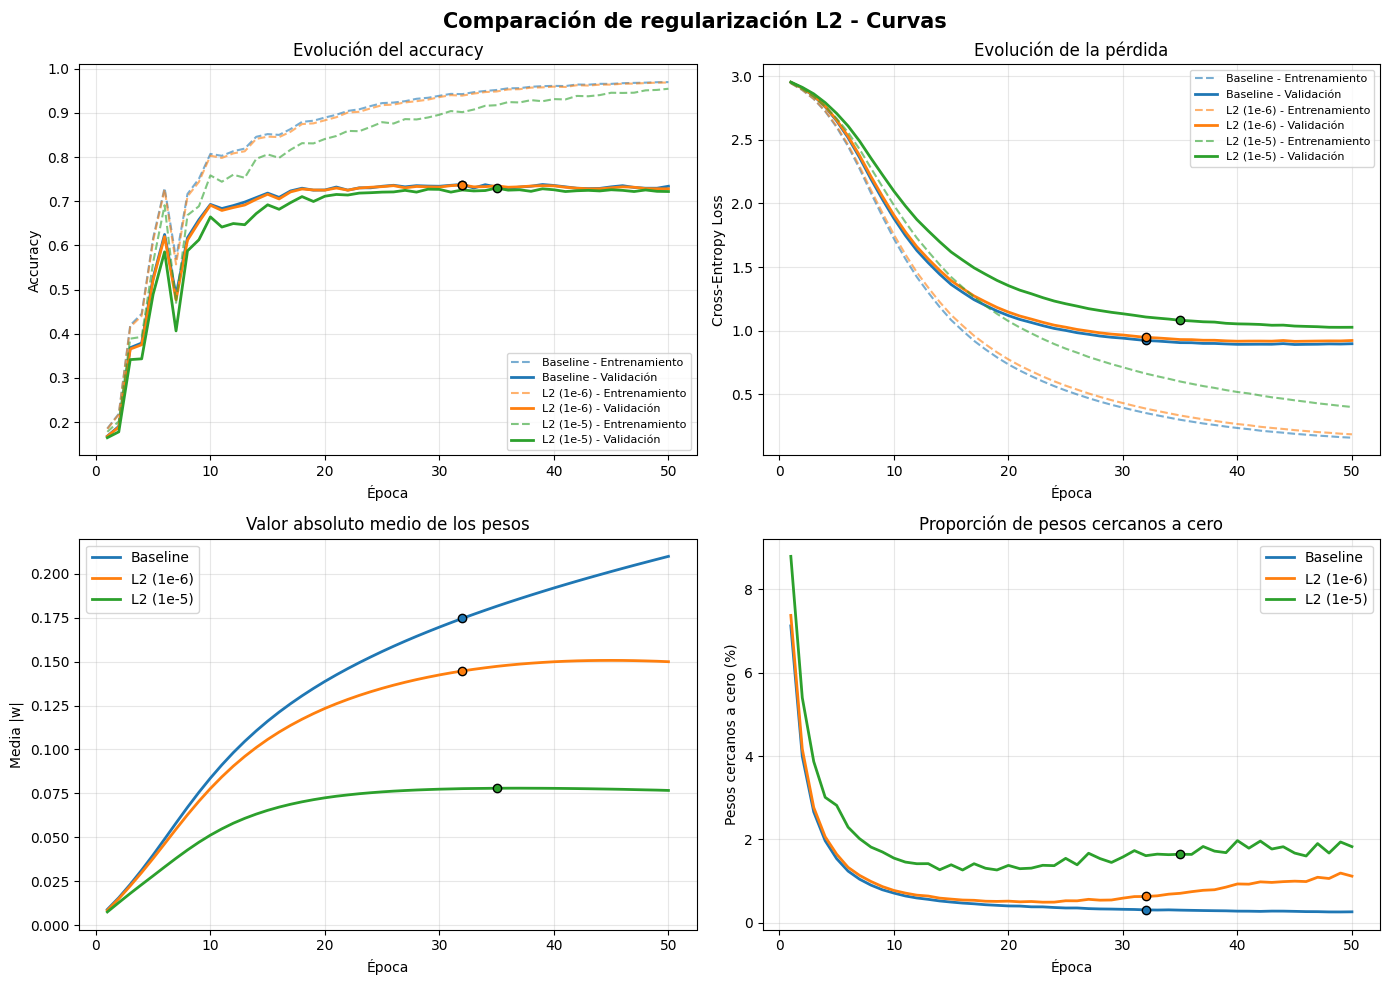

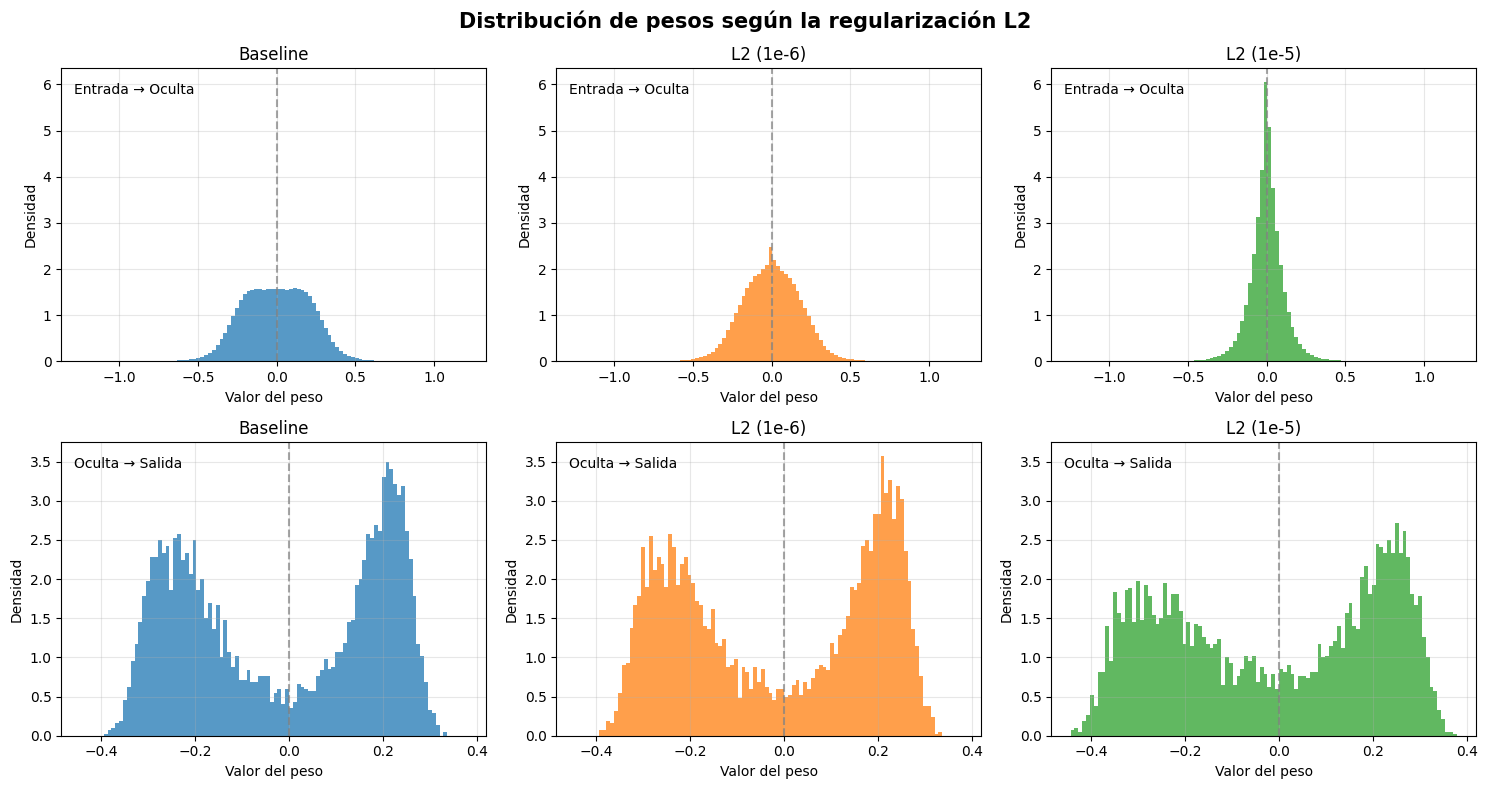

,Baseline,L2 (1e-6),L2 (1e-5)
Mejor época,32,32,35
Accuracy validación,73.80%,73.71%,73.00%
Pérdida validación,0.9234,0.9480,1.0820
Valor absoluto medio,0.1747,0.1447,0.0779
Valor absoluto máximo,1.2069,1.2072,1.2450
Pesos cercanos a cero,0.31%,0.63%,1.64%


In [26]:
# Comparación modelo base, L2 (1e-6) y L2 (1e-5)


# Historiales
experiments = {
    "Baseline": pd.read_csv(RESULTS_DIR / "baseline.csv"),
    "L2 (1e-6)": pd.read_csv(RESULTS_DIR / "l2_1e-6.csv"),
    "L2 (1e-5)": pd.read_csv(RESULTS_DIR / "l2_1e-5.csv")
}

colors = {
    "Baseline": "tab:blue",
    "L2 (1e-6)": "tab:orange",
    "L2 (1e-5)": "tab:green"
}

best_rows = {
    name: df.loc[df["val_acc"].idxmax()]
    for name, df in experiments.items()
}


# Curvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Accuracy
ax = axes[0, 0]

for name, df in experiments.items():

    color = colors[name]
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["train_eval_acc"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )

    ax.plot(
        df["epoch"], df["val_acc"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

    ax.scatter(
        best["epoch"], best["val_acc"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución del accuracy")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


# Cross-Entropy Loss
ax = axes[0, 1]

for name, df in experiments.items():

    color = colors[name]
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["train_eval_loss"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )

    ax.plot(
        df["epoch"], df["val_loss"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

    ax.scatter(
        best["epoch"], best["val_loss"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución de la pérdida")
ax.set_xlabel("Época")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


# Valor absoluto medio de los pesos
ax = axes[1, 0]

for name, df in experiments.items():

    best = best_rows[name]

    ax.plot(
        df["epoch"], df["mean_abs_weight"],
        color=colors[name], linewidth=2,
        label=name
    )

    ax.scatter(
        best["epoch"], best["mean_abs_weight"],
        color=colors[name],
        edgecolor="black", zorder=5
    )

ax.set_title("Valor absoluto medio de los pesos")
ax.set_xlabel("Época")
ax.set_ylabel("Media |w|")
ax.legend()
ax.grid(alpha=0.3)


# Proporción de pesos cercanos a cero
ax = axes[1, 1]

for name, df in experiments.items():

    best = best_rows[name]

    ax.plot(
        df["epoch"], df["fraction_near_zero"] * 100,
        color=colors[name], linewidth=2,
        label=name
    )

    ax.scatter(
        best["epoch"],
        best["fraction_near_zero"] * 100,
        color=colors[name],
        edgecolor="black", zorder=5
    )

ax.set_title("Proporción de pesos cercanos a cero")
ax.set_xlabel("Época")
ax.set_ylabel("Pesos cercanos a cero (%)")
ax.legend()
ax.grid(alpha=0.3)

fig.suptitle(
    "Comparación de regularización L2 - Curvas",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Histogramas
checkpoints = {
    "Baseline": "baseline_best.pth",
    "L2 (1e-6)": "l2_1e-6_best.pth",
    "L2 (1e-5)": "l2_1e-5_best.pth"
}

weights_models = {}

for name, filename in checkpoints.items():

    checkpoint = torch.load(
        MODELS_DIR / filename,
        map_location=device,
        weights_only=True
    )

    model_temp = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=0.0,
        batch_norm=False
    ).to(device)

    model_temp.load_state_dict(checkpoint["model_state_dict"])

    weights_models[name] = [
        module.weight.detach().cpu().numpy().flatten()
        for module in model_temp.modules()
        if isinstance(module, nn.Linear)
    ]


fig, axes = plt.subplots(2, 3, figsize=(15, 8))

layer_names = [
    "Entrada → Oculta",
    "Oculta → Salida"
]

for layer_idx in range(2):

    # Intervalos comunes para los tres modelos
    all_weights = np.concatenate([
        weights_models[name][layer_idx]
        for name in checkpoints
    ])

    bins = np.linspace(
        all_weights.min(),
        all_weights.max(),
        101
    )

    for col, name in enumerate(checkpoints):

        w = weights_models[name][layer_idx]
        ax = axes[layer_idx, col]

        ax.hist(
            w,
            bins=bins,
            density=True,
            color=colors[name],
            alpha=0.75
        )

        ax.axvline(
            0,
            color="gray",
            linestyle="--",
            alpha=0.7
        )

        ax.set_title(name)
        ax.set_xlabel("Valor del peso")
        ax.set_ylabel("Densidad")
        ax.grid(alpha=0.3)

        ax.text(
            0.03, 0.95,
            layer_names[layer_idx],
            transform=ax.transAxes,
            va="top",
            fontsize=10
        )

    # Misma escala vertical dentro de cada fila
    ymax = max(
        axes[layer_idx, col].get_ylim()[1]
        for col in range(3)
    )

    for col in range(3):
        axes[layer_idx, col].set_ylim(0, ymax)

fig.suptitle(
    "Distribución de pesos según la regularización L2",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


display(comparison_l2)

Las curvas de accuracy y pérdida presentan un comportamiento similar al observado con L1. El modelo con mayor penalización, L2 ($\lambda_2=10^{-5}$), muestra un aprendizaje más lento, con un accuracy de entrenamiento menor y una pérdida más elevada. Sin embargo, las diferencias en validación son pequeñas.

- Pesos

Al comparar los resultados con el baseline, se observa que ambos modelos con regularización L2 presentan una menor magnitud promedio de los pesos. Este efecto es más pronunciado para $\lambda_2=10^{-5}$, donde el valor absoluto medio disminuye de 0,1747 a 0,0779. Sin embargo, el valor absoluto máximo de los pesos no disminuye.

La proporción de pesos cercanos a cero también aumenta respecto del baseline, pasando del 0,31 % al 0,63 % y 1,64 %, respectivamente. No obstante, este incremento es considerablemente menor que el observado con L1, lo que refleja las diferencias entre ambas penalizaciones. En L2 la proporción de pesos cercanos a cero tiende a estabilizarse, en cambio, con L1 observamos un crecimiento mucho más pronunciado.

- Histogramas

En los histogramas de los pesos entre la capa de entrada y la capa oculta se observa que la regularización L2 produce una distribución más estrecha y concentrada alrededor de cero. Este efecto es más pronunciado para \$\lambda_2=10^{-5}\$. A diferencia de L1, donde aparecía un pico muy estrecho en cero, con L2 la concentración es más gradual y el pico presenta una mayor anchura.

En los pesos entre la capa oculta y la capa de salida se mantiene una distribución bimodal, similar a la observada con L1. Para $\lambda_2=10^{-6}$, la distribución presenta pocas diferencias respecto del baseline. Con $\lambda_2=10^{-5}$, los picos se vuelven algo menos pronunciados y aumenta la densidad de pesos en la región central.



# Regularización L1+L2


La regularización combinada **L1 + L2** incorpora simultáneamente ambas penalizaciones a la función de pérdida:

$$
\mathcal{L}_{\text{total}}
=
\mathcal{L}_{CE}
+
\lambda_1 \sum_{i=1}^{N}|w_i|
+
\lambda_2 \sum_{i=1}^{N}w_i^2
$$

La penalización L1 favorece la aparición de pesos cercanos a cero, mientras que L2 penaliza especialmente los pesos de mayor magnitud. Su combinación permite estudiar el efecto conjunto de ambos mecanismos sobre los parámetros de la red.

En este experimento se utilizan $\lambda_1=10^{-7}$ y $\lambda_2=10^{-6}$, coeficientes que fueron evaluados individualmente y permitieron observar los efectos característicos de cada regularización sobre los pesos.

Se mantiene la misma arquitectura, optimizador y cantidad de épocas del baseline para comparar los resultados.



In [27]:
# Experimento L1 + L2
L1_LAMBDA = 1e-7
L2_LAMBDA = 1e-6

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_l1_l2 = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.0,
    batch_norm=False
).to(device)

optimizer_l1_l2 = torch.optim.Adam(
    model_l1_l2.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)

history_l1_l2 = train_mlp_model(
    model=model_l1_l2,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_l1_l2,
    epochs=50,
    run_name="l1_1e-7_l2_1e-6",
    l1_lambda=L1_LAMBDA,
    l2_lambda=L2_LAMBDA,
    max_norm=None,
    early_stopping_patience=None
)

Experimento 'l1_1e-7_l2_1e-6' recuperado.
No es necesario volver a entrenar.
Mejor época: 32
Mejor accuracy validación: 0.7371


In [28]:
df_l1_l2 = pd.DataFrame(history_l1_l2)

best_l1_l2 = df_l1_l2.loc[df_l1_l2["val_acc"].idxmax()]

print("=== RESULTADOS L1 + L2 ===")
print(f"Mejor época: {int(best_l1_l2['epoch'])}")
print(f"Accuracy de validación: {best_l1_l2['val_acc']:.2%}")
print(f"Pérdida de validación: {best_l1_l2['val_loss']:.4f}")
print(f"Valor absoluto medio: {best_l1_l2['mean_abs_weight']:.6f}")
print(f"Valor absoluto máximo: {best_l1_l2['max_abs_weight']:.6f}")
print(f"Pesos cercanos a cero: {best_l1_l2['fraction_near_zero']:.2%}")

=== RESULTADOS L1 + L2 ===
Mejor época: 32
Accuracy de validación: 73.71%
Pérdida de validación: 0.9554
Valor absoluto medio: 0.134265
Valor absoluto máximo: 1.217998
Pesos cercanos a cero: 4.16%


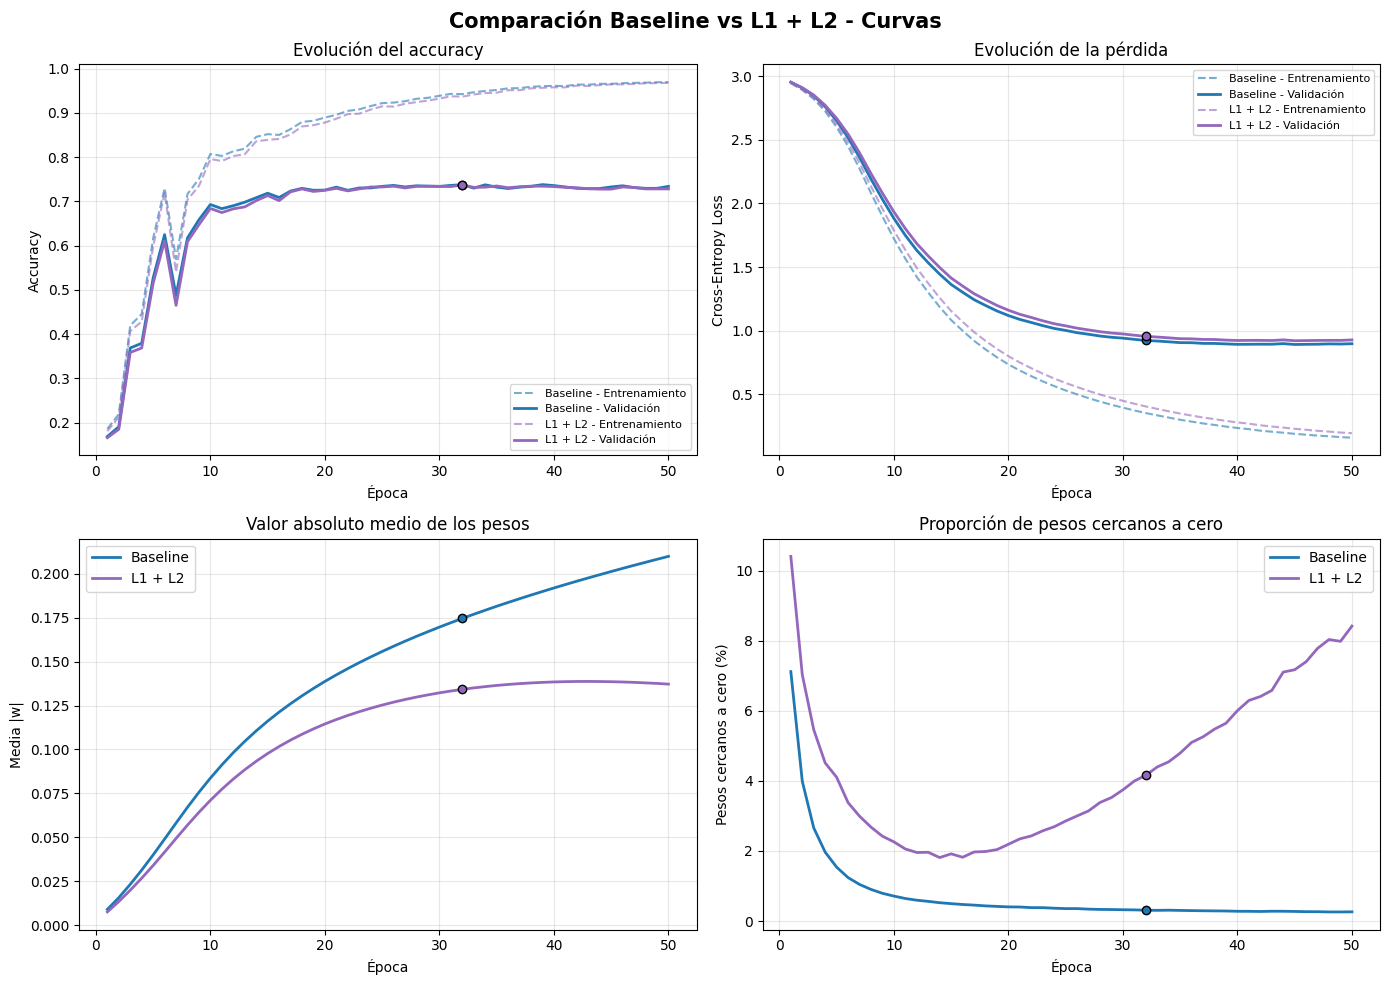

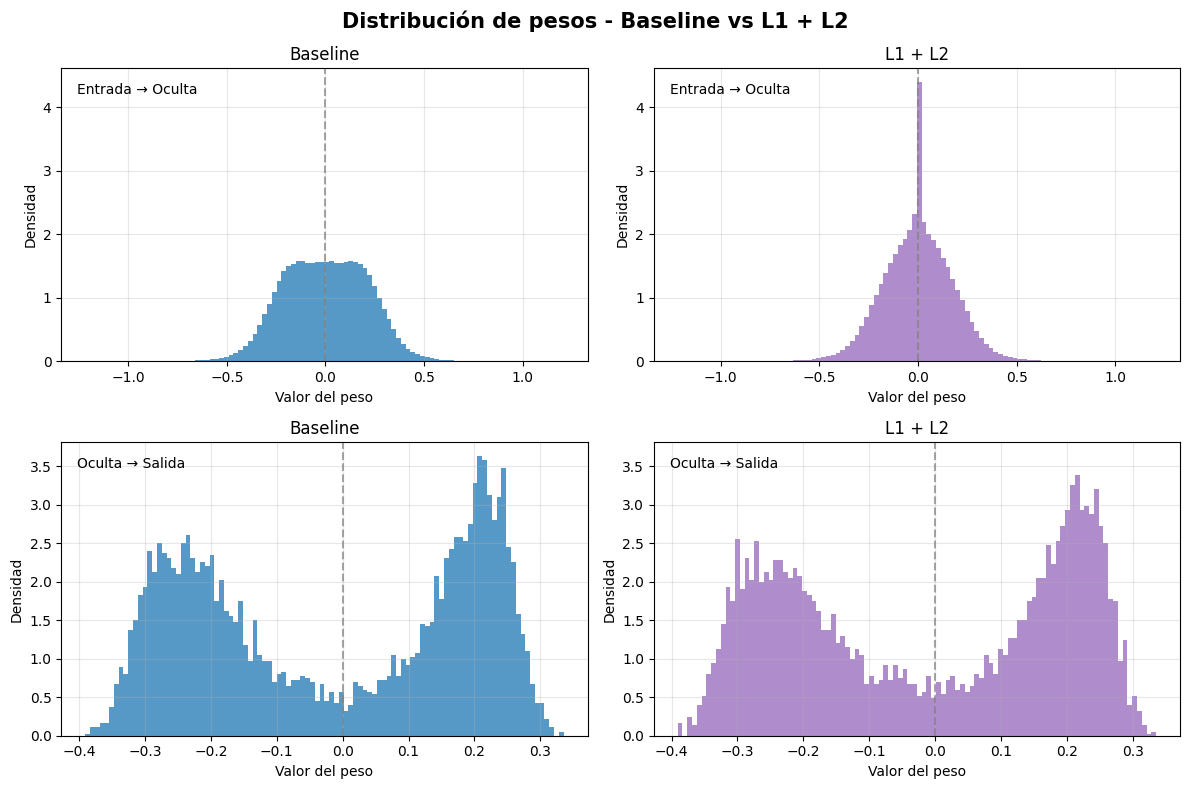

,Baseline,L1 + L2
Métrica,,
Mejor época,32,32
Accuracy entrenamiento,94.25%,93.68%
Accuracy validación,73.80%,73.71%
Pérdida entrenamiento,0.3535,0.4050
Pérdida validación,0.9234,0.9554
Valor absoluto medio,0.1747,0.1343
Valor absoluto máximo,1.2069,1.2180
Pesos cercanos a cero,0.31%,4.16%


In [29]:
# Comparación modelo base y L1+L2

# Historiales
experiments = {
    "Baseline": pd.read_csv(RESULTS_DIR / "baseline.csv"),
    "L1 + L2": pd.read_csv(
        RESULTS_DIR / "l1_1e-7_l2_1e-6.csv"
    )
}

colors = {
    "Baseline": "tab:blue",
    "L1 + L2": "tab:purple"
}

best_rows = {
    name: df.loc[df["val_acc"].idxmax()]
    for name, df in experiments.items()
}


# Curvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Accuracy
ax = axes[0, 0]

for name, df in experiments.items():

    color = colors[name]
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["train_eval_acc"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )

    ax.plot(
        df["epoch"], df["val_acc"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

    ax.scatter(
        best["epoch"], best["val_acc"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución del accuracy")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


# Cross-Entropy Loss
ax = axes[0, 1]

for name, df in experiments.items():

    color = colors[name]
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["train_eval_loss"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )

    ax.plot(
        df["epoch"], df["val_loss"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

    ax.scatter(
        best["epoch"], best["val_loss"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución de la pérdida")
ax.set_xlabel("Época")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


# Valor absoluto medio de los pesos
ax = axes[1, 0]

for name, df in experiments.items():

    best = best_rows[name]

    ax.plot(
        df["epoch"], df["mean_abs_weight"],
        color=colors[name], linewidth=2,
        label=name
    )

    ax.scatter(
        best["epoch"], best["mean_abs_weight"],
        color=colors[name],
        edgecolor="black", zorder=5
    )

ax.set_title("Valor absoluto medio de los pesos")
ax.set_xlabel("Época")
ax.set_ylabel("Media |w|")
ax.legend()
ax.grid(alpha=0.3)


# Proporción de pesos cercanos a cero
ax = axes[1, 1]

for name, df in experiments.items():

    best = best_rows[name]

    ax.plot(
        df["epoch"], df["fraction_near_zero"] * 100,
        color=colors[name], linewidth=2,
        label=name
    )

    ax.scatter(
        best["epoch"],
        best["fraction_near_zero"] * 100,
        color=colors[name],
        edgecolor="black", zorder=5
    )

ax.set_title("Proporción de pesos cercanos a cero")
ax.set_xlabel("Época")
ax.set_ylabel("Pesos cercanos a cero (%)")
ax.legend()
ax.grid(alpha=0.3)

fig.suptitle(
    "Comparación Baseline vs L1 + L2 - Curvas",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Histogramas
checkpoints = {
    "Baseline": "baseline_best.pth",
    "L1 + L2": "l1_1e-7_l2_1e-6_best.pth"
}

weights_models = {}

for name, filename in checkpoints.items():

    checkpoint = torch.load(
        MODELS_DIR / filename,
        map_location=device,
        weights_only=True
    )

    model_temp = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=0.0,
        batch_norm=False
    ).to(device)

    model_temp.load_state_dict(
        checkpoint["model_state_dict"]
    )

    weights_models[name] = [
        module.weight.detach().cpu().numpy().flatten()
        for module in model_temp.modules()
        if isinstance(module, nn.Linear)
    ]


fig, axes = plt.subplots(2, 2, figsize=(12, 8))

layer_names = [
    "Entrada → Oculta",
    "Oculta → Salida"
]

for layer_idx in range(2):

    all_weights = np.concatenate([
        weights_models[name][layer_idx]
        for name in checkpoints
    ])

    bins = np.linspace(
        all_weights.min(),
        all_weights.max(),
        101
    )

    for col, name in enumerate(checkpoints):

        w = weights_models[name][layer_idx]
        ax = axes[layer_idx, col]

        ax.hist(
            w,
            bins=bins,
            density=True,
            color=colors[name],
            alpha=0.75
        )

        ax.axvline(
            0,
            color="gray",
            linestyle="--",
            alpha=0.7
        )

        ax.set_title(name)
        ax.set_xlabel("Valor del peso")
        ax.set_ylabel("Densidad")
        ax.grid(alpha=0.3)

        ax.text(
            0.03, 0.95,
            layer_names[layer_idx],
            transform=ax.transAxes,
            va="top",
            fontsize=10
        )

    # Misma escala vertical dentro de cada fila
    ymax = max(
        axes[layer_idx, col].get_ylim()[1]
        for col in range(2)
    )

    for col in range(2):
        axes[layer_idx, col].set_ylim(0, ymax)

fig.suptitle(
    "Distribución de pesos - Baseline vs L1 + L2",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Tabla
best_base = best_rows["Baseline"]
best_combined = best_rows["L1 + L2"]

metrics = {
    "epoch": "Mejor época",
    "train_eval_acc": "Accuracy entrenamiento",
    "val_acc": "Accuracy validación",
    "train_eval_loss": "Pérdida entrenamiento",
    "val_loss": "Pérdida validación",
    "mean_abs_weight": "Valor absoluto medio",
    "max_abs_weight": "Valor absoluto máximo",
    "fraction_near_zero": "Pesos cercanos a cero"
}

rows = []

for key, label in metrics.items():

    base = best_base[key]
    combined = best_combined[key]

    if key == "epoch":
        base_str = f"{int(base)}"
        combined_str = f"{int(combined)}"

    elif key in [
        "train_eval_acc",
        "val_acc",
        "fraction_near_zero"
    ]:
        base_str = f"{base:.2%}"
        combined_str = f"{combined:.2%}"

    else:
        decimals = 2 if key == "weight_l2_norm" else 4

        base_str = f"{base:.{decimals}f}"
        combined_str = f"{combined:.{decimals}f}"

    rows.append({
        "Métrica": label,
        "Baseline": base_str,
        "L1 + L2": combined_str
    })

comparison_combined = pd.DataFrame(rows).set_index("Métrica")

display(comparison_combined)

- Curvas accuracy y pérdida

Las curvas de accuracy y pérdida de la regularización combinada L1 + L2 presentan un comportamiento muy similar al del baseline, sin mejoras apreciables en el desempeño de validación. Además, se mantiene la separación entre las curvas de entrenamiento y validación, lo que indica que el sobreajuste continúa presente.

- Pesos

En cuanto a los pesos, el modelo combinado presenta un valor absoluto medio menor que el baseline, pasando de 0,1747 a 0,1343 en la mejor época. Esto muestra que la combinación de ambas penalizaciones limita el crecimiento de la magnitud de los pesos.

Por otro lado, la proporción de pesos cercanos a cero presenta un comportamiento similar al observado con L1: inicialmente disminuye y luego comienza a aumentar progresivamente. En la mejor época, alcanza un 4,16 %, frente al 0,31 % del baseline.

Este comportamiento es consistente con el efecto de L1, que favorece la concentración de pesos alrededor de cero. Sin embargo, el incremento es menor que el observado con L1 ($10^{-6}$), donde la proporción alcanzó el 28,00 % en la mejor época.

- Histograma

En los histogramas de los pesos entre la capa de entrada y la capa oculta se observan los efectos de ambas regularizaciones. La distribución es más estrecha y presenta una mayor concentración de pesos alrededor de cero, comportamiento asociado a L2. Además, aparece un pico muy pronunciado y estrecho en cero, característico de la penalización L1.

En los pesos entre la capa oculta y la capa de salida se mantiene una distribución bimodal, similar a la del baseline, aunque se observa un ligero aumento de la densidad en la región central.

Comparación de las regularizaciones L1, L2 y L1 + L2

En general, las tres regularizaciones presentan curvas de accuracy y pérdida similares a las del baseline. Aunque los modelos con mayor penalización muestran un aprendizaje algo más lento, ninguno de los coeficientes evaluados logró mejorar el accuracy de validación ni eliminar el sobreajuste.

Las principales diferencias se observan en la magnitud y distribución de los pesos. La regularización L1 favorece una mayor concentración de pesos alrededor de cero. Además, después de las primeras épocas, la proporción de pesos cercanos a cero comienza a aumentar progresivamente, especialmente para el coeficiente de penalización más elevado.

Por otro lado, L2 también reduce la magnitud de los pesos, pero de manera más distribuida. En lugar de generar un pico tan pronunciado en cero, produce distribuciones más estrechas, con una mayor concentración de pesos pequeños. La proporción de pesos cercanos a cero también aumenta respecto del baseline, aunque en menor medida que con L1 y con una tendencia más estable durante el entrenamiento.

Finalmente, la combinación L1 + L2 presenta características de ambas técnicas: reduce la magnitud promedio de los pesos y, al mismo tiempo, favorece su concentración alrededor de cero.


# Regularización Dropout


La regularización **Dropout** consiste en desactivar aleatoriamente una proporción de las activaciones de las neuronas durante el entrenamiento. Esto evita que la red dependa excesivamente de determinadas neuronas y favorece el aprendizaje de representaciones más robustas.

La proporción de activaciones desactivadas se controla mediante el parámetro $p$. Por ejemplo, con $p=0.2$, cada activación tiene una probabilidad del 20 % de ser desactivada durante una pasada de entrenamiento.

A diferencia de L1 y L2, Dropout no incorpora una penalización adicional a la función de pérdida. Durante la evaluación, Dropout se desactiva y se utiliza la red completa.

En este experimento se evaluarán dos probabilidades de Dropout, $p=0.2$ y $p=0.5$, manteniendo la misma arquitectura y los hiperparámetros de entrenamiento del baseline.

In [30]:
# Dropout p=0.2

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_dropout_02 = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.2,
    batch_norm=False
).to(device)

optimizer_dropout_02 = torch.optim.Adam(
    model_dropout_02.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)

history_dropout_02 = train_mlp_model(
    model=model_dropout_02,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_dropout_02,
    epochs=50,
    run_name="dropout_0.2",
    l1_lambda=0.0,
    l2_lambda=0.0,
    early_stopping_patience=None
)

Experimento 'dropout_0.2' recuperado.
No es necesario volver a entrenar.
Mejor época: 45
Mejor accuracy validación: 0.7393


In [31]:
# Dropout p=0.5

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_dropout_05 = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.5,
    batch_norm=False
).to(device)

optimizer_dropout_05 = torch.optim.Adam(
    model_dropout_05.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)

history_dropout_05 = train_mlp_model(
    model=model_dropout_05,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_dropout_05,
    epochs=50,
    run_name="dropout_0.5",
    l1_lambda=0.0,
    l2_lambda=0.0,
    early_stopping_patience=None
)

Experimento 'dropout_0.5' recuperado.
No es necesario volver a entrenar.
Mejor época: 49
Mejor accuracy validación: 0.7375


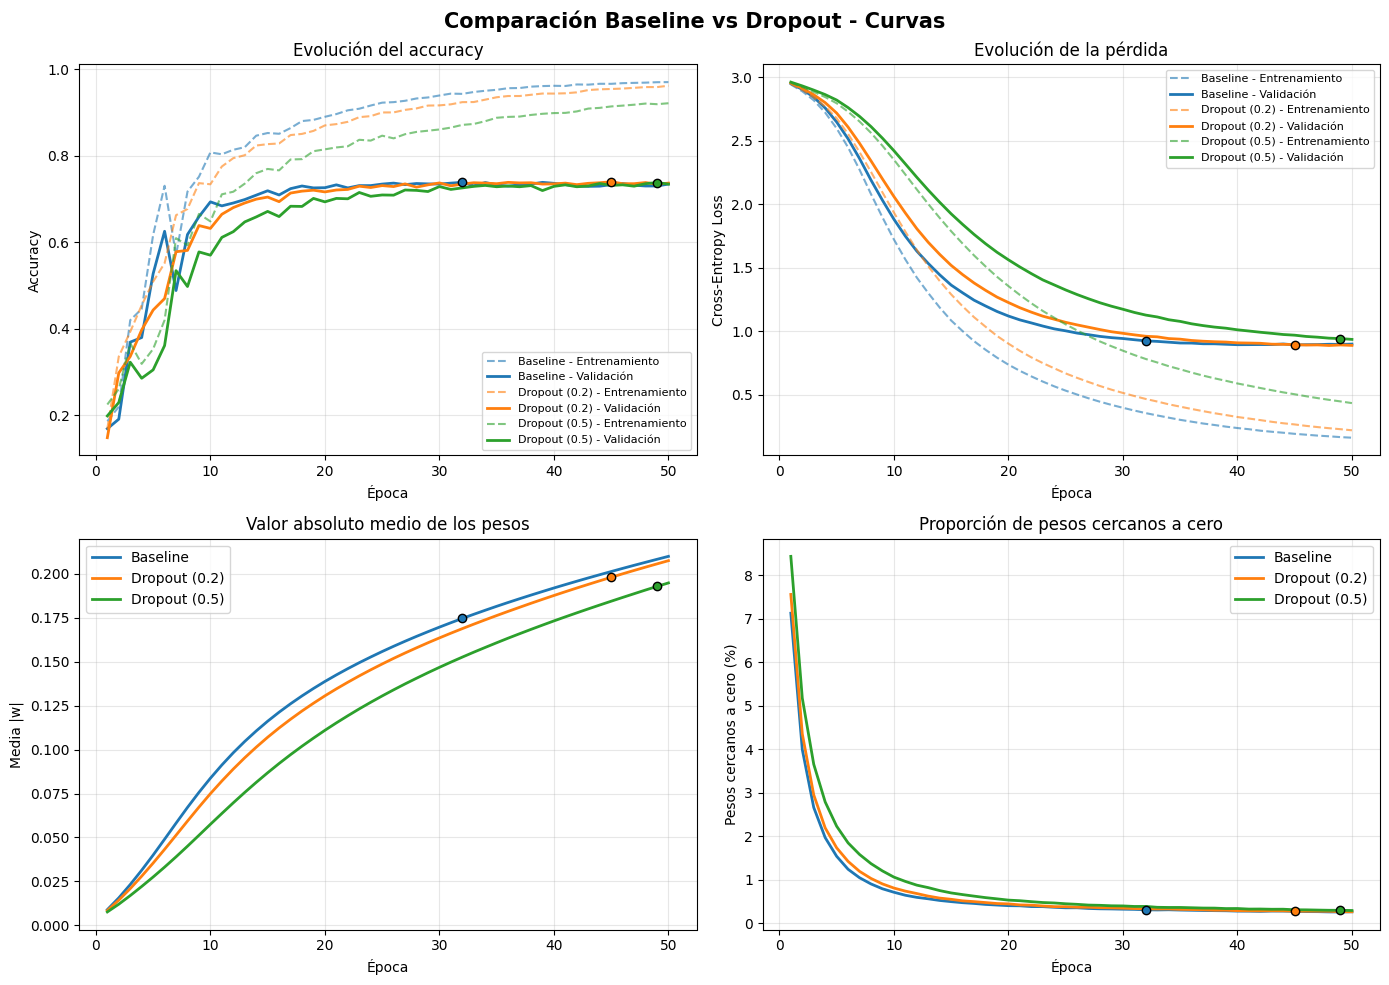

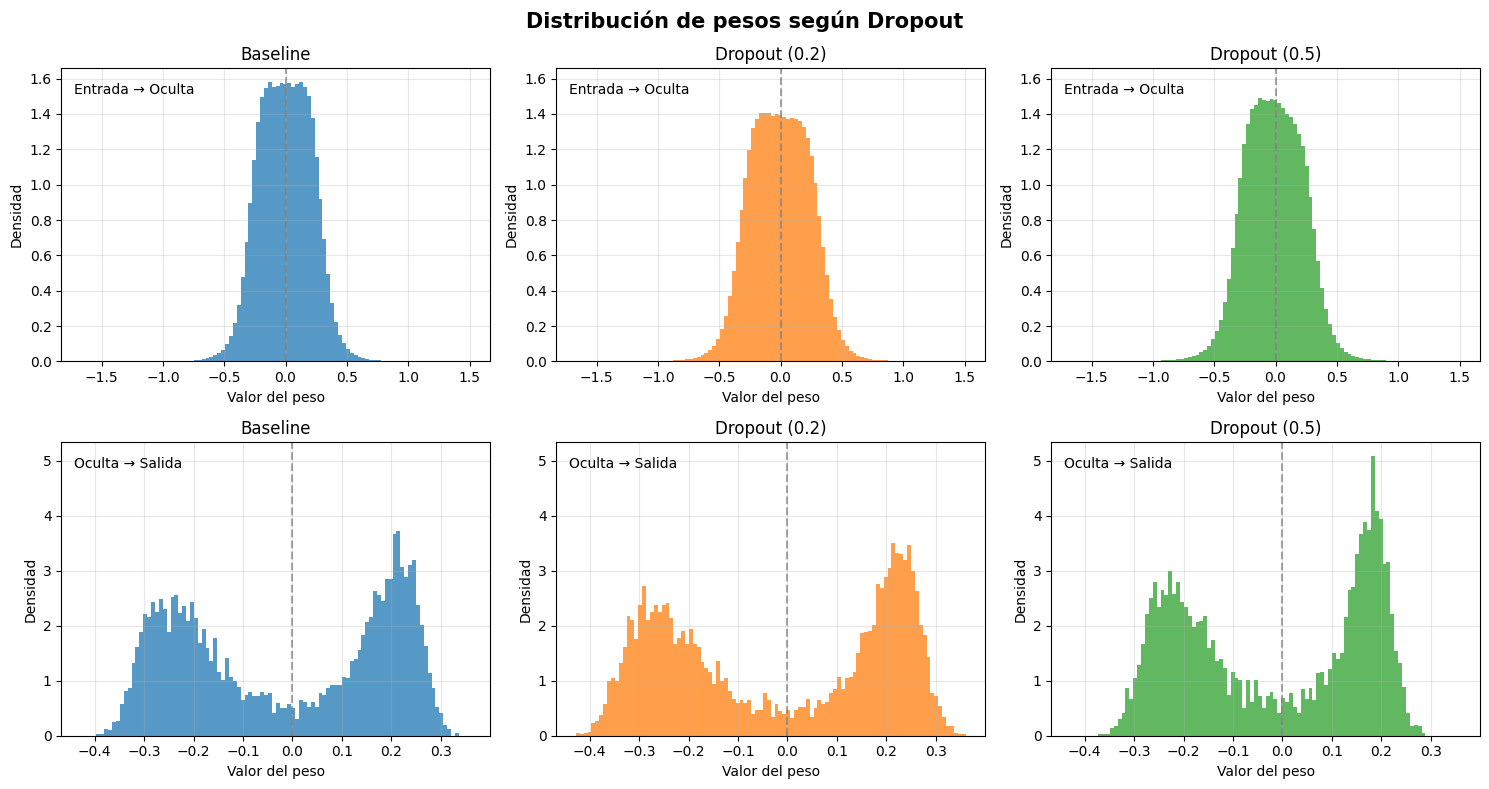

,Baseline,Dropout (0.2),Dropout (0.5)
Mejor época,32,45,49
Accuracy entrenamiento,94.25%,95.38%,91.87%
Accuracy validación,73.80%,73.93%,73.75%
Pérdida entrenamiento,0.3535,0.2643,0.4459
Pérdida validación,0.9234,0.8940,0.9416
Valor absoluto medio,0.1747,0.1981,0.1929
Valor absoluto máximo,1.2069,1.4623,1.6684
Pesos cercanos a cero,0.31%,0.28%,0.30%


In [32]:
# Comparación de modelo base y drpout (0.2 y 0.5)

experiments = {
    "Baseline": pd.read_csv(RESULTS_DIR / "baseline.csv"),
    "Dropout (0.2)": pd.read_csv(RESULTS_DIR / "dropout_0.2.csv"),
    "Dropout (0.5)": pd.read_csv(RESULTS_DIR / "dropout_0.5.csv")
}

colors = {
    "Baseline": "tab:blue",
    "Dropout (0.2)": "tab:orange",
    "Dropout (0.5)": "tab:green"
}

best_rows = {
    name: df.loc[df["val_acc"].idxmax()]
    for name, df in experiments.items()
}


# Curvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Accuracy
ax = axes[0, 0]

for name, df in experiments.items():
    best = best_rows[name]
    color = colors[name]

    ax.plot(
        df["epoch"], df["train_eval_acc"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )

    ax.plot(
        df["epoch"], df["val_acc"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

    ax.scatter(
        best["epoch"], best["val_acc"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución del accuracy")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


# Cross-Entropy Loss
ax = axes[0, 1]

for name, df in experiments.items():
    best = best_rows[name]
    color = colors[name]

    ax.plot(
        df["epoch"], df["train_eval_loss"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )

    ax.plot(
        df["epoch"], df["val_loss"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

    ax.scatter(
        best["epoch"], best["val_loss"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución de la pérdida")
ax.set_xlabel("Época")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


# Valor absoluto medio de los pesos
ax = axes[1, 0]

for name, df in experiments.items():
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["mean_abs_weight"],
        color=colors[name], linewidth=2, label=name
    )

    ax.scatter(
        best["epoch"], best["mean_abs_weight"],
        color=colors[name], edgecolor="black", zorder=5
    )

ax.set_title("Valor absoluto medio de los pesos")
ax.set_xlabel("Época")
ax.set_ylabel("Media |w|")
ax.legend()
ax.grid(alpha=0.3)


# Proporción de pesos cercanos a cero
ax = axes[1, 1]

for name, df in experiments.items():
    best = best_rows[name]

    ax.plot(
        df["epoch"], df["fraction_near_zero"] * 100,
        color=colors[name], linewidth=2, label=name
    )

    ax.scatter(
        best["epoch"], best["fraction_near_zero"] * 100,
        color=colors[name], edgecolor="black", zorder=5
    )

ax.set_title("Proporción de pesos cercanos a cero")
ax.set_xlabel("Época")
ax.set_ylabel("Pesos cercanos a cero (%)")
ax.legend()
ax.grid(alpha=0.3)

fig.suptitle(
    "Comparación Baseline vs Dropout - Curvas",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()
plt.show()


# Histogramas
checkpoints = {
    "Baseline": "baseline_best.pth",
    "Dropout (0.2)": "dropout_0.2_best.pth",
    "Dropout (0.5)": "dropout_0.5_best.pth"
}

weights_models = {}

for name, filename in checkpoints.items():

    checkpoint = torch.load(
        MODELS_DIR / filename,
        map_location=device,
        weights_only=True
    )

    dropout_p = {
        "Baseline": 0.0,
        "Dropout (0.2)": 0.2,
        "Dropout (0.5)": 0.5
    }[name]

    model_temp = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=dropout_p,
        batch_norm=False
    ).to(device)

    model_temp.load_state_dict(checkpoint["model_state_dict"])

    weights_models[name] = [
        module.weight.detach().cpu().numpy().flatten()
        for module in model_temp.modules()
        if isinstance(module, nn.Linear)
    ]


fig, axes = plt.subplots(2, 3, figsize=(15, 8))

layer_names = [
    "Entrada → Oculta",
    "Oculta → Salida"
]

for layer_idx in range(2):

    all_weights = np.concatenate([
        weights_models[name][layer_idx]
        for name in checkpoints
    ])

    bins = np.linspace(
        all_weights.min(),
        all_weights.max(),
        101
    )

    for col, name in enumerate(checkpoints):

        ax = axes[layer_idx, col]
        w = weights_models[name][layer_idx]

        ax.hist(
            w,
            bins=bins,
            density=True,
            color=colors[name],
            alpha=0.75
        )

        ax.axvline(
            0, color="gray", linestyle="--", alpha=0.7
        )

        ax.set_title(name)
        ax.set_xlabel("Valor del peso")
        ax.set_ylabel("Densidad")
        ax.grid(alpha=0.3)

        ax.text(
            0.03, 0.95,
            layer_names[layer_idx],
            transform=ax.transAxes,
            va="top",
            fontsize=10
        )

    ymax = max(
        axes[layer_idx, col].get_ylim()[1]
        for col in range(3)
    )

    for col in range(3):
        axes[layer_idx, col].set_ylim(0, ymax)

fig.suptitle(
    "Distribución de pesos según Dropout",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()
plt.show()


# Tabla
metrics = {
    "epoch": "Mejor época",
    "train_eval_acc": "Accuracy entrenamiento",
    "val_acc": "Accuracy validación",
    "train_eval_loss": "Pérdida entrenamiento",
    "val_loss": "Pérdida validación",
    "mean_abs_weight": "Valor absoluto medio",
    "max_abs_weight": "Valor absoluto máximo",
    "fraction_near_zero": "Pesos cercanos a cero"
}

results = {}

for name, best in best_rows.items():

    results[name] = {}

    for key, label in metrics.items():

        value = best[key]

        if key == "epoch":
            formatted = f"{int(value)}"

        elif key in [
            "train_eval_acc",
            "val_acc",
            "fraction_near_zero"
        ]:
            formatted = f"{value:.2%}"

        else:
            decimals = 2 if key == "weight_l2_norm" else 4
            formatted = f"{value:.{decimals}f}"

        results[name][label] = formatted

comparison_dropout = pd.DataFrame(results)

display(comparison_dropout)

- Curvas de accuracy y pérdida

En las curvas de accuracy y pérdida se observa que los modelos con Dropout presentan una convergencia más lenta que el baseline. El accuracy aumenta de manera más gradual y la pérdida disminuye más lentamente, especialmente para Dropout con $p=0.5$.

Además, la separación entre las curvas de entrenamiento y validación es menor en los modelos con Dropout, particularmente para $p=0.5$. Esto indica una reducción de la brecha entre ambos conjuntos, aunque a medida que pasan las epocas va aumentando y acercandose al comportamiento del modelo base.

- Pesos

En cuanto a la evolución de los pesos, los modelos con Dropout mantienen un comportamiento similar al baseline.

El valor absoluto medio aumenta progresivamente durante el entrenamiento, aunque alcanza valores ligeramente menores, especialmente con $p=0.5$.

Por otro lado, la proporción de pesos cercanos a cero, si bien inicialmente es algo mayor en los modelos con Dropout, las diferencias se reducen con el avance del entrenamiento, hasta alcanzar valores muy similares a los del baseline.

- Histogramas

Los histogramas muestran que los modelos con Dropout mantienen distribuciones de pesos muy similares a las del baseline.

Aunque existen pequeñas variaciones en la densidad y posición de los picos, no se identifica una modificación marcada de la distribución al aumentar la probabilidad de Dropout.



En conclusión, a diferencia de las regularizaciones L1, L2 y L1 + L2, cuyos efectos más notorios se observaron en la magnitud y distribución de los pesos, Dropout produjo cambios más evidentes en las curvas de aprendizaje. Los modelos con Dropout presentaron una convergencia más lenta y una menor separación entre las curvas de entrenamiento y validación, especialmente para $p=0.5$. En cambio, la evolución y distribución de los pesos se mantuvieron relativamente similares a las del baseline.

Estos resultados sugieren que Dropout puede ser útil para reducir el sobreajuste, ya que disminuye la diferencia entre el desempeño de entrenamiento y validación.

## Regularización Dropout + Max-Norm

La técnica **Max-Norm** establece un límite máximo para la norma de los vectores de pesos asociados a cada neurona:

$$
\|\mathbf{w}_i\|_2 \leq c
$$

donde $c$ es el límite establecido.

A diferencia de L1 y L2, Max-Norm no incorpora una penalización adicional a la función de pérdida. Después de cada actualización del optimizador, los vectores cuya norma supera el límite se reescalan para satisfacer la restricción.

En este experimento se combina Max-Norm con Dropout ($p=0.2$), utilizando dos límites: $c=20$ y $c=25$.

Estos valores se seleccionaron a partir del análisis de las normas de los pesos del modelo entrenado con Dropout. Dado que se aplica el mismo límite a todas las capas lineales, se espera que la restricción actúe principalmente sobre la primera capa.

In [33]:
# Normas de pesos - Dropout p=0.2
checkpoint = torch.load(
    MODELS_DIR / "dropout_0.2_best.pth",
    map_location=device,
    weights_only=True
)

model_temp = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.2,
    batch_norm=False
).to(device)

model_temp.load_state_dict(checkpoint["model_state_dict"])

for name, module in model_temp.named_modules():

    if isinstance(module, nn.Linear):

        # Norma L2 por neurona (filas de la matriz)
        norms = torch.linalg.vector_norm(
            module.weight.detach(),
            ord=2,
            dim=1
        ).cpu().numpy()

        print(f"\nCapa: {name}")
        print(f"Cantidad de neuronas: {len(norms)}")
        print(f"Norma mínima: {norms.min():.4f}")
        print(f"Norma media: {norms.mean():.4f}")
        print(f"Norma máxima: {norms.max():.4f}")
        print(f"Percentil 25: {np.percentile(norms, 25):.4f}")
        print(f"Percentil 50: {np.percentile(norms, 50):.4f}")
        print(f"Percentil 75: {np.percentile(norms, 75):.4f}")


Capa: network.0
Cantidad de neuronas: 256
Norma mínima: 22.2844
Norma media: 24.0986
Norma máxima: 25.4795
Percentil 25: 23.7949
Percentil 50: 24.0706
Percentil 75: 24.3891

Capa: network.3
Cantidad de neuronas: 20
Norma mínima: 3.3402
Norma media: 3.6129
Norma máxima: 3.8652
Percentil 25: 3.4908
Percentil 50: 3.6178
Percentil 75: 3.7502


In [34]:
# Dropout p=0.2 + Max-norm
max_norm_values = [20, 25]

histories_maxnorm = {}

for c in max_norm_values:

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=0.2,
        batch_norm=False
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR,
        betas=(BETA1, BETA2),
        weight_decay=0.0
    )

    run_name = f"dropout_0.2_maxnorm_{c}"

    print(f"\nEntrenando {run_name}")

    histories_maxnorm[c] = train_mlp_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        epochs=50,
        run_name=run_name,
        l1_lambda=0.0,
        l2_lambda=0.0,
        max_norm=c,
        early_stopping_patience=None
    )


Entrenando dropout_0.2_maxnorm_20
Experimento 'dropout_0.2_maxnorm_20' recuperado.
No es necesario volver a entrenar.
Mejor época: 36
Mejor accuracy validación: 0.7388

Entrenando dropout_0.2_maxnorm_25
Experimento 'dropout_0.2_maxnorm_25' recuperado.
No es necesario volver a entrenar.
Mejor época: 45
Mejor accuracy validación: 0.7393


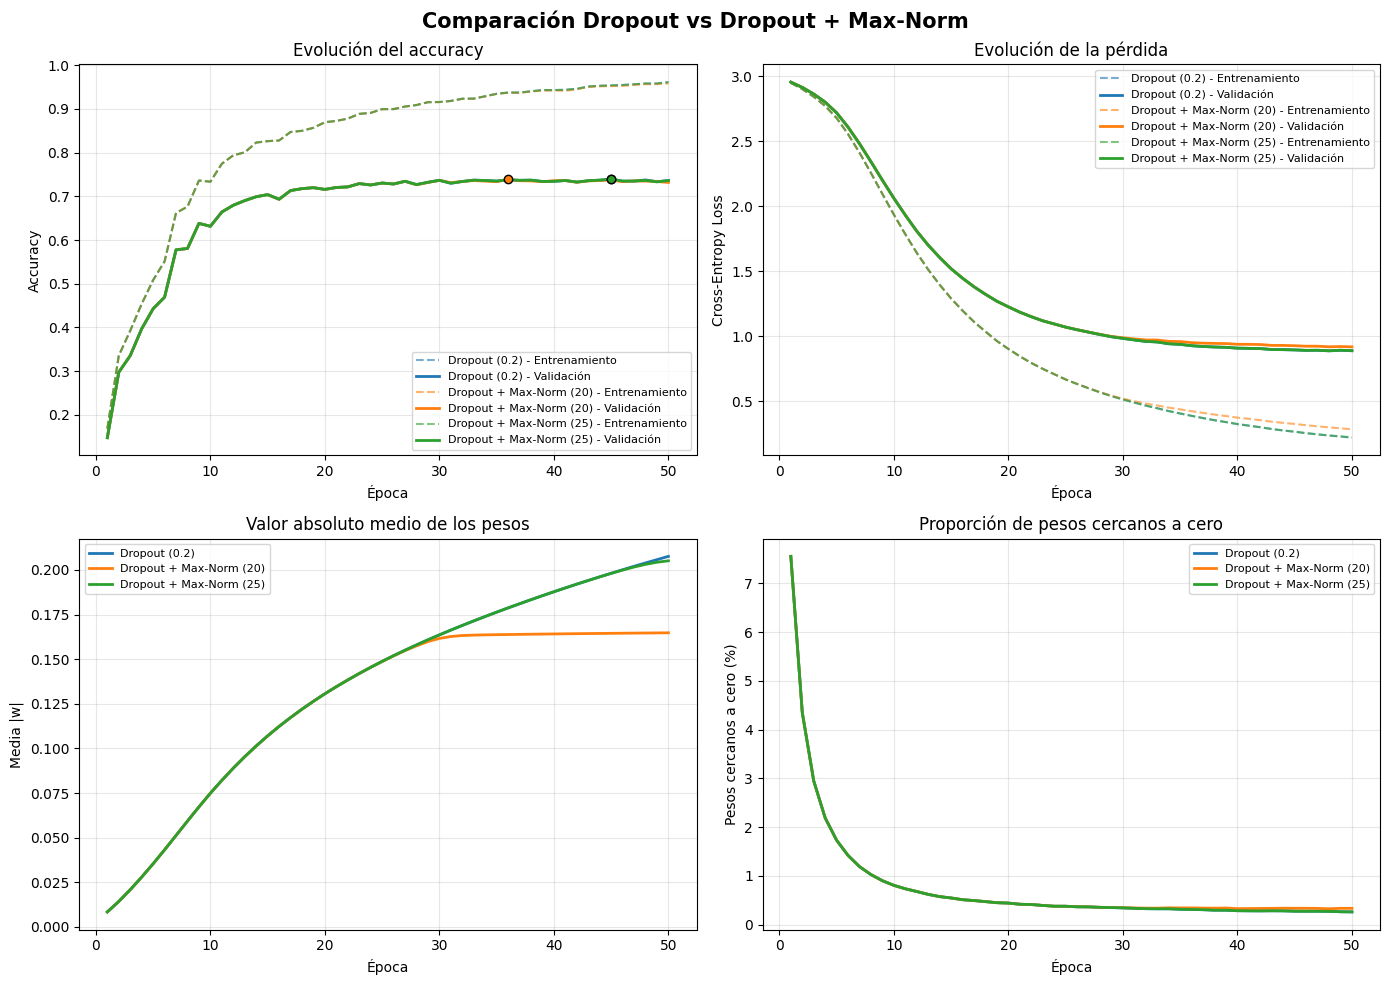

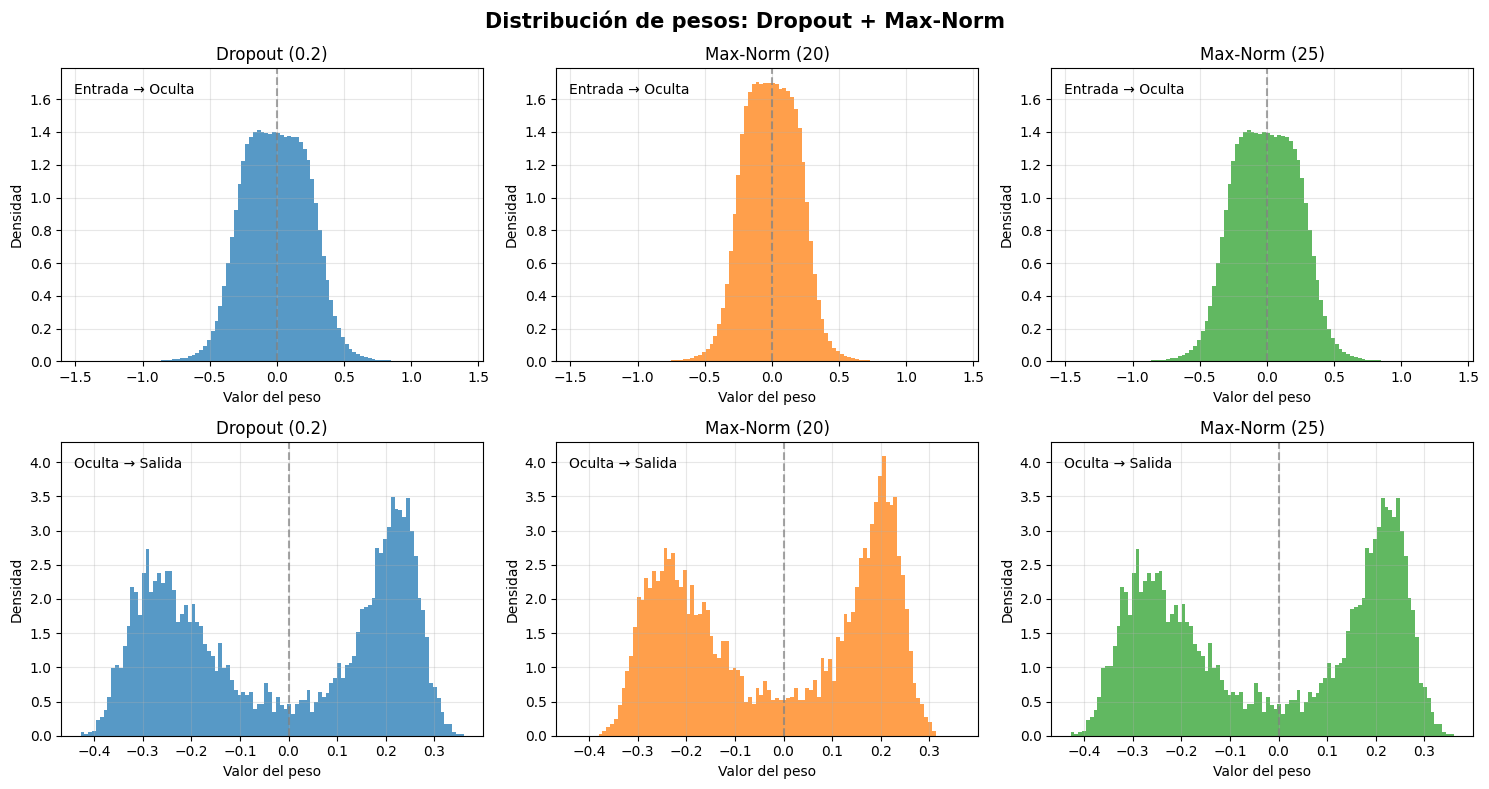

,Dropout (0.2),Max-Norm (20),Max-Norm (25)
Mejor época,45,36,45
Accuracy entrenamiento,95.38%,93.70%,95.38%
Accuracy validación,73.93%,73.88%,73.93%
Pérdida entrenamiento,0.2643,0.4223,0.2644
Pérdida validación,0.8940,0.9502,0.8941
Valor absoluto medio,0.1981,0.1638,0.1980
Valor absoluto máximo,1.4623,1.2211,1.4623
Norma L2 global,385.98,320.31,385.81
Pesos cercanos a cero,0.28%,0.35%,0.28%


,Modelo,Capa,Norma mínima,Norma media,Norma máxima,Límite,Neuronas en el límite (%)
0,Dropout (0.2),Entrada → Oculta,22.284,24.099001,25.479,Sin límite,NaN
1,Dropout (0.2),Oculta → Salida,3.340,3.613000,3.865,Sin límite,NaN
2,Dropout + Max-Norm (20),Entrada → Oculta,20.000,20.000000,20.000,20,100.000
3,Dropout + Max-Norm (20),Oculta → Salida,2.906,3.231000,3.502,20,0.000
4,Dropout + Max-Norm (25),Entrada → Oculta,22.285,24.087999,25.000,25,4.297
5,Dropout + Max-Norm (25),Oculta → Salida,3.340,3.613000,3.865,25,0.000


In [35]:
experiments_maxnorm = {
    "Dropout (0.2)": pd.read_csv(
        RESULTS_DIR / "dropout_0.2.csv"
    ),
    "Dropout + Max-Norm (20)": pd.read_csv(
        RESULTS_DIR / "dropout_0.2_maxnorm_20.csv"
    ),
    "Dropout + Max-Norm (25)": pd.read_csv(
        RESULTS_DIR / "dropout_0.2_maxnorm_25.csv"
    )
}

colors = {
    "Dropout (0.2)": "tab:blue",
    "Dropout + Max-Norm (20)": "tab:orange",
    "Dropout + Max-Norm (25)": "tab:green"
}

best_rows_maxnorm = {
    name: df.loc[df["val_acc"].idxmax()]
    for name, df in experiments_maxnorm.items()
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Accuracy
ax = axes[0, 0]

for name, df in experiments_maxnorm.items():
    color = colors[name]
    best = best_rows_maxnorm[name]

    ax.plot(
        df["epoch"], df["train_eval_acc"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )
    ax.plot(
        df["epoch"], df["val_acc"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )
    ax.scatter(
        best["epoch"], best["val_acc"],
        color=color, edgecolor="black", zorder=5
    )

ax.set_title("Evolución del accuracy")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Pérdida
ax = axes[0, 1]

for name, df in experiments_maxnorm.items():
    color = colors[name]

    ax.plot(
        df["epoch"], df["train_eval_loss"],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name} - Entrenamiento"
    )
    ax.plot(
        df["epoch"], df["val_loss"],
        color=color, linewidth=2,
        label=f"{name} - Validación"
    )

ax.set_title("Evolución de la pérdida")
ax.set_xlabel("Época")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Valor absoluto medio
ax = axes[1, 0]

for name, df in experiments_maxnorm.items():
    ax.plot(
        df["epoch"], df["mean_abs_weight"],
        color=colors[name], linewidth=2, label=name
    )

ax.set_title("Valor absoluto medio de los pesos")
ax.set_xlabel("Época")
ax.set_ylabel("Media |w|")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Pesos cercanos a cero
ax = axes[1, 1]

for name, df in experiments_maxnorm.items():
    ax.plot(
        df["epoch"], df["fraction_near_zero"] * 100,
        color=colors[name], linewidth=2, label=name
    )

ax.set_title("Proporción de pesos cercanos a cero")
ax.set_xlabel("Época")
ax.set_ylabel("Pesos cercanos a cero (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

fig.suptitle(
    "Comparación Dropout vs Dropout + Max-Norm",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()
plt.show()


# Histogramas
model_configs = {
    "Dropout (0.2)": "dropout_0.2_best.pth",
    "Max-Norm (20)": "dropout_0.2_maxnorm_20_best.pth",
    "Max-Norm (25)": "dropout_0.2_maxnorm_25_best.pth"
}

colors = {
    "Dropout (0.2)": "tab:blue",
    "Max-Norm (20)": "tab:orange",
    "Max-Norm (25)": "tab:green"
}

weights_models = {}

for name, filename in model_configs.items():

    checkpoint = torch.load(
        MODELS_DIR / filename,
        map_location=device,
        weights_only=True
    )

    model_temp = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=0.2,
        batch_norm=False
    ).to(device)

    model_temp.load_state_dict(checkpoint["model_state_dict"])

    weights_models[name] = [
        module.weight.detach().cpu().numpy().flatten()
        for module in model_temp.modules()
        if isinstance(module, nn.Linear)
    ]


fig, axes = plt.subplots(2, 3, figsize=(15, 8))

layer_names = [
    "Entrada → Oculta",
    "Oculta → Salida"
]

for layer_idx in range(2):

    all_weights = np.concatenate([
        weights_models[name][layer_idx]
        for name in model_configs
    ])

    bins = np.linspace(
        all_weights.min(),
        all_weights.max(),
        101
    )

    for col, name in enumerate(model_configs):

        ax = axes[layer_idx, col]
        weights = weights_models[name][layer_idx]

        ax.hist(
            weights,
            bins=bins,
            density=True,
            color=colors[name],
            alpha=0.75
        )

        ax.axvline(
            0,
            color="gray",
            linestyle="--",
            alpha=0.7
        )

        ax.set_title(name)
        ax.set_xlabel("Valor del peso")
        ax.set_ylabel("Densidad")
        ax.grid(alpha=0.3)

        ax.text(
            0.03, 0.95,
            layer_names[layer_idx],
            transform=ax.transAxes,
            va="top"
        )

    # Misma escala vertical dentro de cada capa
    ymax = max(
        axes[layer_idx, col].get_ylim()[1]
        for col in range(3)
    )

    for col in range(3):
        axes[layer_idx, col].set_ylim(0, ymax)

fig.suptitle(
    "Distribución de pesos: Dropout + Max-Norm",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



# Tabla
experiments_maxnorm = {
    "Dropout (0.2)": "dropout_0.2",
    "Max-Norm (20)": "dropout_0.2_maxnorm_20",
    "Max-Norm (25)": "dropout_0.2_maxnorm_25"
}

best_rows_maxnorm = {}

for name, filename in experiments_maxnorm.items():

    df = pd.read_csv(
        RESULTS_DIR / f"{filename}.csv"
    )

    best_rows_maxnorm[name] = df.loc[
        df["val_acc"].idxmax()
    ]

metrics = {
    "epoch": "Mejor época",
    "train_eval_acc": "Accuracy entrenamiento",
    "val_acc": "Accuracy validación",
    "train_eval_loss": "Pérdida entrenamiento",
    "val_loss": "Pérdida validación",
    "mean_abs_weight": "Valor absoluto medio",
    "max_abs_weight": "Valor absoluto máximo",
    "weight_l2_norm": "Norma L2 global",
    "fraction_near_zero": "Pesos cercanos a cero"
}

results = {}

for name, best in best_rows_maxnorm.items():

    results[name] = {}

    for key, label in metrics.items():

        value = best[key]

        if key == "epoch":
            formatted = f"{int(value)}"

        elif key in [
            "train_eval_acc",
            "val_acc",
            "fraction_near_zero"
        ]:
            formatted = f"{value:.2%}"

        else:
            decimals = 2 if key == "weight_l2_norm" else 4
            formatted = f"{value:.{decimals}f}"

        results[name][label] = formatted

comparison_maxnorm = pd.DataFrame(results)

display(comparison_maxnorm)



# Norma L2 por neurona
model_configs = {
    "Dropout (0.2)": ("dropout_0.2_best.pth", None),
    "Dropout + Max-Norm (20)": ("dropout_0.2_maxnorm_20_best.pth", 20),
    "Dropout + Max-Norm (25)": ("dropout_0.2_maxnorm_25_best.pth", 25)
}

norms_by_model = {}
rows = []

for name, (filename, limit) in model_configs.items():

    checkpoint = torch.load(
        MODELS_DIR / filename,
        map_location=device,
        weights_only=True
    )

    model_temp = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=0.2,
        batch_norm=False
    ).to(device)

    model_temp.load_state_dict(checkpoint["model_state_dict"])
    model_temp.eval()

    norms_by_model[name] = []

    for layer_idx, module in enumerate(
        m for m in model_temp.modules()
        if isinstance(m, nn.Linear)
    ):

        norms = torch.linalg.vector_norm(
            module.weight.detach(),
            ord=2,
            dim=1
        ).cpu().numpy()

        norms_by_model[name].append(norms)

        rows.append({
            "Modelo": name,
            "Capa": ["Entrada → Oculta", "Oculta → Salida"][layer_idx],
            "Norma mínima": norms.min(),
            "Norma media": norms.mean(),
            "Norma máxima": norms.max(),
            "Límite": limit if limit is not None else "Sin límite",
            "Neuronas en el límite (%)": (
                100 * np.mean(np.isclose(norms, limit, atol=1e-3))
                if limit is not None else np.nan
            )
        })

norms_table = pd.DataFrame(rows)

display(norms_table.round(3))

Las curvas de accuracy y pérdida de los modelos con Dropout + Max-Norm presentan un comportamiento prácticamente idéntico al del modelo con únicamente Dropout, sin diferencias apreciables en la dinámica de entrenamiento ni en el desempeño de validación.

Sin embargo, al analizar las normas L2 de los pesos por neurona, se observa que **Max-Norm actúa principalmente sobre la primera capa**, ya que las normas de la segunda permanecen por debajo de los límites establecidos. Para $c=20$, el 100 % de las neuronas de la primera capa alcanza el límite, mientras que para $c=25$ solamente lo hace el 4,30 %.

Esta diferencia permite explicar el comportamiento observado en la evolución del valor absoluto medio de los pesos. Con $c=20$, la curva deja de crecer alrededor de la época 30 y se estabiliza, lo que es consistente con una restricción activa sobre la magnitud de los vectores de pesos. En cambio, con $c=25$, la curva prácticamente coincide con la del modelo sin Max-Norm, debido a que la restricción tiene un efecto mucho menor.

Los histogramas muestran que las distribuciones de pesos de Dropout y Dropout + Max-Norm (25) son prácticamente idénticas. En cambio, con Max-Norm (20) se observa una distribución más estrecha y concentrada alrededor de cero en la primera capa. Este comportamiento es consistente con el análisis de las normas L2 por neurona, que mostró que la restricción actúa principalmente sobre esta capa y es considerablemente más intensa para $c=20$.

En conjunto, los resultados muestran que **Max-Norm logró limitar el crecimiento de los pesos, especialmente con $c=20$, pero sin producir cambios apreciables en el desempeño de validación**.

# Bach Normalization

En esta sección se evalúa el efecto de **Batch Normalization** sobre el entrenamiento de la red neuronal. Esta técnica normaliza los valores que llegan a las funciones de activación utilizando la media y la varianza de cada minibatch, con el objetivo de facilitar y estabilizar el proceso de optimización.

Para incorporarla, se agrega una capa `BatchNorm1d` entre la transformación lineal y la función de activación Sigmoid de la capa oculta. Se mantienen los mismos hiperparámetros del baseline.


In [36]:
# Batch normalization

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_bn = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    activation=ACTIVATION,
    dropout=0.0,
    batch_norm=True
).to(device)


optimizer_bn = torch.optim.Adam(
    model_bn.parameters(),
    lr=LR,
    betas=(BETA1, BETA2),
    weight_decay=0.0
)


history_bn = train_mlp_model(
    model=model_bn,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_bn,
    epochs=50,
    run_name="batchnorm",
    l1_lambda=0.0,
    l2_lambda=0.0,
    max_norm=None,
    early_stopping_patience=None
)

Experimento 'batchnorm' recuperado.
No es necesario volver a entrenar.
Mejor época: 1
Mejor accuracy validación: 0.7238


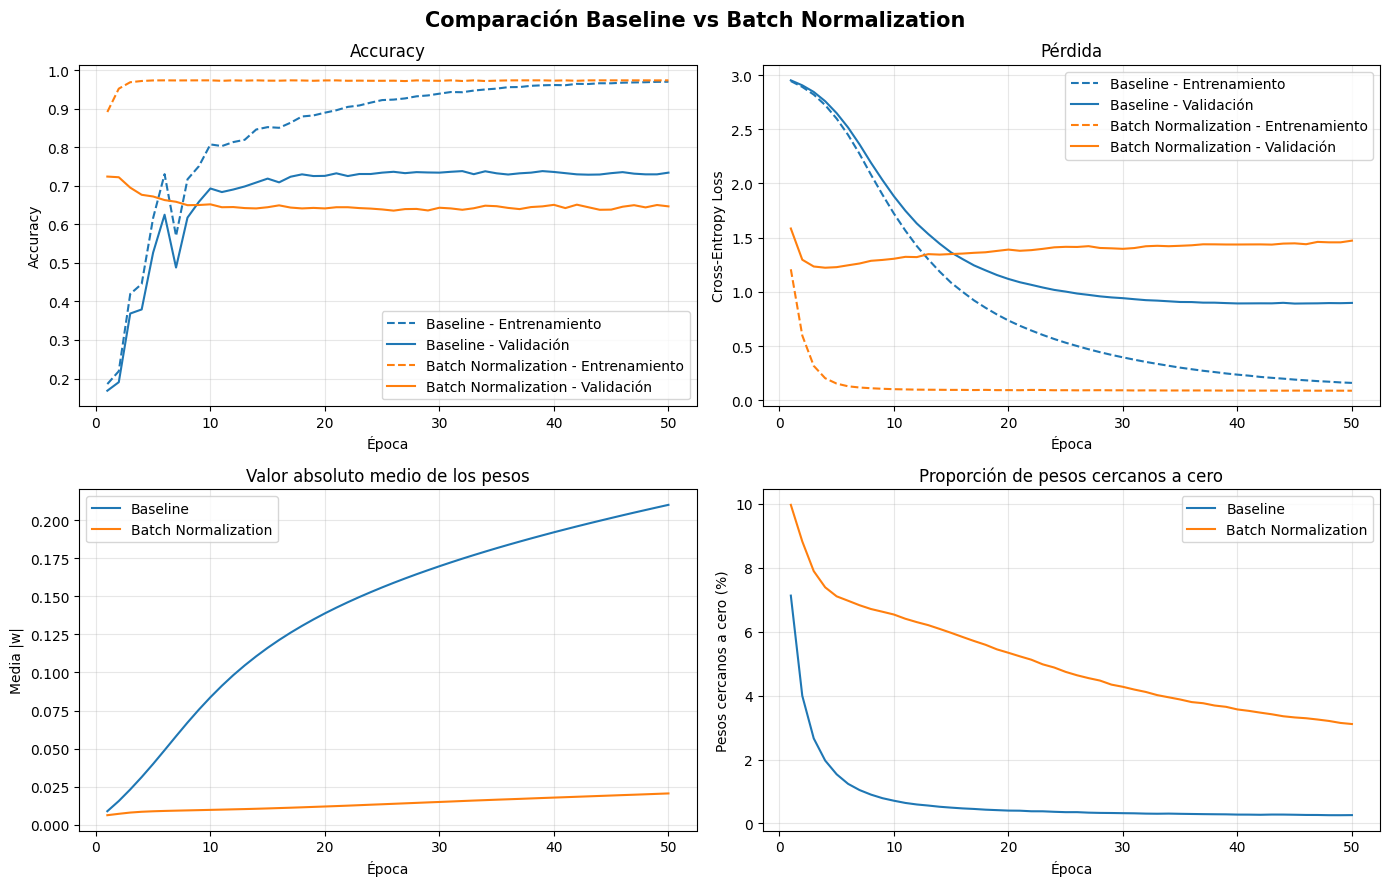

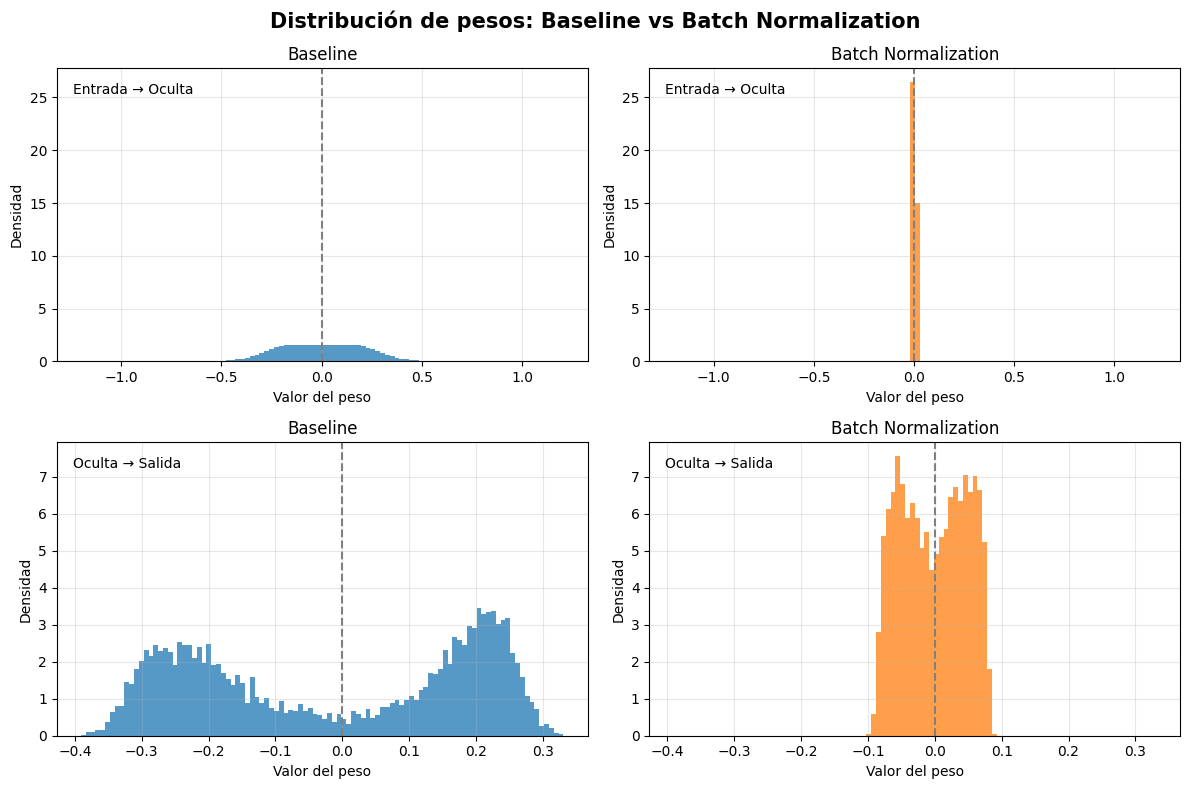

,Baseline,Batch Normalization
Mejor época,32,1
Accuracy entrenamiento,94.25%,89.13%
Accuracy validación,73.80%,72.38%
Pérdida entrenamiento,0.3535,1.2083
Pérdida validación,0.9234,1.5846
Valor absoluto medio,0.1747,0.0063
Valor absoluto máximo,1.2069,0.0972
Pesos cercanos a cero,0.31%,9.96%


In [37]:
# Comparación del modelo base y con batch nomelization

experiments_bn = {
    "Baseline": pd.read_csv(RESULTS_DIR / "baseline.csv"),
    "Batch Normalization": pd.read_csv(RESULTS_DIR / "batchnorm.csv")
}

colors = {
    "Baseline": "tab:blue",
    "Batch Normalization": "tab:orange"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Accuracy
ax = axes[0, 0]

for name, df in experiments_bn.items():
    ax.plot(
        df["epoch"], df["train_eval_acc"],
        "--", color=colors[name],
        label=f"{name} - Entrenamiento"
    )
    ax.plot(
        df["epoch"], df["val_acc"],
        color=colors[name],
        label=f"{name} - Validación"
    )

ax.set_title("Accuracy")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.grid(alpha=0.3)
ax.legend()

# Pérdida
ax = axes[0, 1]

for name, df in experiments_bn.items():
    ax.plot(
        df["epoch"], df["train_eval_loss"],
        "--", color=colors[name],
        label=f"{name} - Entrenamiento"
    )
    ax.plot(
        df["epoch"], df["val_loss"],
        color=colors[name],
        label=f"{name} - Validación"
    )

ax.set_title("Pérdida")
ax.set_xlabel("Época")
ax.set_ylabel("Cross-Entropy Loss")
ax.grid(alpha=0.3)
ax.legend()

# Valor absoluto medio de los pesos
ax = axes[1, 0]

for name, df in experiments_bn.items():
    ax.plot(
        df["epoch"], df["mean_abs_weight"],
        color=colors[name],
        label=name
    )

ax.set_title("Valor absoluto medio de los pesos")
ax.set_xlabel("Época")
ax.set_ylabel("Media |w|")
ax.grid(alpha=0.3)
ax.legend()

# Pesos cercanos a cero
ax = axes[1, 1]

for name, df in experiments_bn.items():
    ax.plot(
        df["epoch"], df["fraction_near_zero"] * 100,
        color=colors[name],
        label=name
    )

ax.set_title("Proporción de pesos cercanos a cero")
ax.set_xlabel("Época")
ax.set_ylabel("Pesos cercanos a cero (%)")
ax.grid(alpha=0.3)
ax.legend()

fig.suptitle(
    "Comparación Baseline vs Batch Normalization",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Histogramas
configs = {
    "Baseline": ("baseline_best.pth", False),
    "Batch Normalization": ("batchnorm_best.pth", True)
}

colors = {
    "Baseline": "tab:blue",
    "Batch Normalization": "tab:orange"
}

weights_models = {}

for name, (filename, use_bn) in configs.items():

    checkpoint = torch.load(
        MODELS_DIR / filename,
        map_location=device,
        weights_only=True
    )

    model_temp = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=0.0,
        batch_norm=use_bn
    ).to(device)

    model_temp.load_state_dict(checkpoint["model_state_dict"])

    weights_models[name] = [
        module.weight.detach().cpu().numpy().flatten()
        for module in model_temp.modules()
        if isinstance(module, nn.Linear)
    ]

# Gráficos
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

layer_names = ["Entrada → Oculta", "Oculta → Salida"]

for layer_idx in range(2):

    all_weights = np.concatenate([
        weights_models[name][layer_idx]
        for name in configs
    ])

    bins = np.linspace(
        all_weights.min(),
        all_weights.max(),
        101
    )

    for col, name in enumerate(configs):

        ax = axes[layer_idx, col]
        weights = weights_models[name][layer_idx]

        ax.hist(
            weights,
            bins=bins,
            density=True,
            color=colors[name],
            alpha=0.75
        )

        ax.axvline(0, color="gray", linestyle="--")

        ax.set_title(name)
        ax.set_xlabel("Valor del peso")
        ax.set_ylabel("Densidad")
        ax.grid(alpha=0.3)

        ax.text(
            0.03, 0.95,
            layer_names[layer_idx],
            transform=ax.transAxes,
            va="top"
        )

    # Misma escala vertical para ambos modelos
    ymax = max(axes[layer_idx, col].get_ylim()[1] for col in range(2))

    for col in range(2):
        axes[layer_idx, col].set_ylim(0, ymax)

fig.suptitle(
    "Distribución de pesos: Baseline vs Batch Normalization",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Tabla
experiments = {
    "Baseline": "baseline",
    "Batch Normalization": "batchnorm"
}

best_rows = {}

for name, filename in experiments.items():

    df = pd.read_csv(RESULTS_DIR / f"{filename}.csv")

    best_rows[name] = df.loc[df["val_acc"].idxmax()]

metrics = {
    "epoch": "Mejor época",
    "train_eval_acc": "Accuracy entrenamiento",
    "val_acc": "Accuracy validación",
    "train_eval_loss": "Pérdida entrenamiento",
    "val_loss": "Pérdida validación",
    "mean_abs_weight": "Valor absoluto medio",
    "max_abs_weight": "Valor absoluto máximo",
    "fraction_near_zero": "Pesos cercanos a cero"
}

results = {}

for name, best in best_rows.items():

    results[name] = {}

    for key, label in metrics.items():

        value = best[key]

        if key == "epoch":
            formatted = f"{int(value)}"

        elif key in ["train_eval_acc", "val_acc", "fraction_near_zero"]:
            formatted = f"{value:.2%}"

        else:
            decimals = 2 if key == "weight_l2_norm" else 4
            formatted = f"{value:.{decimals}f}"

        results[name][label] = formatted

comparison_bn = pd.DataFrame(results)

display(comparison_bn)

- Accuracy y pérdida

Al incorporar Batch Normalization, se observa un cambio importante en las curvas de aprendizaje respecto del baseline. El accuracy de entrenamiento alcanza valores cercanos al 90 % desde la primera época y aumenta rápidamente hasta aproximadamente el 97 %, donde se estabiliza. En cambio, el accuracy de validación comienza alrededor del 72 % y disminuye durante las primeras épocas, hasta estabilizarse cerca del 65 %.

Este comportamiento sugiere que Batch Normalization facilita una convergencia inicial más rápida. Sin embargo, como las métricas se registran al finalizar cada época, no es posible observar el crecimiento del accuracy durante los primeros minibatches. A diferencia del baseline, donde la separación entre entrenamiento y validación aparece progresivamente, con Batch Normalization esta diferencia ya es considerable desde la primera época.

Las curvas de pérdida muestran un comportamiento similar al anterior. La pérdida de entrenamiento disminuye rápidamente y permanece en valores bajos, mientras que la pérdida de validación, después de una reducción inicial, comienza a aumentar.

El mejor accuracy de validación se alcanza en la época 1, con un valor de 72,38 %, ligeramente inferior al 73,80 % obtenido por el baseline. Por lo tanto, aunque Batch Normalization acelera considerablemente el aprendizaje inicial, en esta configuración no mejora el desempeño de validación.

- Pesos

Las curvas de evolución de los pesos muestran un comportamiento diferente al observado en el baseline. El valor absoluto medio de los pesos aumenta de manera mucho más gradual con Batch Normalization y se mantiene considerablemente por debajo del baseline durante todo el entrenamiento.

Por otro lado, la proporción de pesos cercanos a cero disminuye más lentamente que en el modelo base y permanece en valores superiores durante las 50 épocas. Esto es consistente con el menor crecimiento de la magnitud de los pesos.

- Histogramas

Los histogramas muestran diferencias importantes en la distribución de los pesos respecto del baseline. En la capa de entrada a oculta, Batch Normalization presenta una concentración muy pronunciada alrededor de cero, acompañada de una reducción considerable del valor absoluto medio.

En la capa oculta a salida, la distribución conserva dos máximos, pero estos se encuentran mucho más próximos entre sí y al cero. A diferencia del baseline, donde la bimodalidad es claramente pronunciada, con Batch Normalization los pesos se concentran principalmente entre −0,1 y 0,1.

El efecto de Batch Normalization se observa tanto en las curvas de aprendizaje como en la evolución de los pesos.



# Tiempos

In [38]:
experimentos = {
    "Baseline": "baseline",
    "L1 (1e-7)": "l1_1e-7",
    "L1 (1e-6)": "l1_1e-6",
    "L2 (1e-6)": "l2_1e-6",
    "L2 (1e-5)": "l2_1e-5",
    "L1 + L2": "l1_1e-7_l2_1e-6",
    "Dropout (0.2)": "dropout_0.2",
    "Dropout (0.5)": "dropout_0.5",
    "Dropout + MaxNorm (20)": "dropout_0.2_maxnorm_20",
    "Dropout + MaxNorm (25)": "dropout_0.2_maxnorm_25",
    "Batch Normalization": "batchnorm"
}

resultados_convergencia = []

for nombre, archivo in experimentos.items():

    df = pd.read_csv(RESULTS_DIR / f"{archivo}.csv")

    idx_mejor = df["val_acc"].idxmax()
    mejor_epoca = int(df.loc[idx_mejor, "epoch"])

    tiempo_hasta_mejor = df.loc[:idx_mejor, "epoch_time"].sum()
    tiempo_total = df["epoch_time"].sum()

    resultados_convergencia.append({
        "Modelo": nombre,
        "Mejor época": mejor_epoca,
        "Tiempo hasta mejor época (s)": tiempo_hasta_mejor,
        "Tiempo total (s)": tiempo_total,
        "Mejor accuracy val. (%)": df.loc[idx_mejor, "val_acc"] * 100
    })

df_convergencia = pd.DataFrame(resultados_convergencia)

display(df_convergencia.round(2))

,Modelo,Mejor época,Tiempo hasta mejor época (s),Tiempo total (s),Mejor accuracy val. (%)
0,Baseline,32,223.73,337.28,73.80
1,L1 (1e-7),32,346.60,554.65,73.71
2,L1 (1e-6),40,370.76,450.14,73.66
3,L2 (1e-6),32,286.11,435.95,73.71
4,L2 (1e-5),35,309.92,460.63,73.00
5,L1 + L2,32,287.29,448.00,73.71
6,Dropout (0.2),45,310.44,343.31,73.93
7,Dropout (0.5),49,332.31,338.45,73.75
8,Dropout + MaxNorm (20),36,266.37,361.08,73.88
9,Dropout + MaxNorm (25),45,310.19,344.78,73.93


Al comparar los tiempos de entrenamiento, se observa que L1 y L2 son las técnicas que requieren más tiempo, sin lograr mejoras en el accuracy de validación respecto del baseline.

Por otro lado, Dropout tiene un tiempo por época similar al baseline, pero necesita más épocas para alcanzar su mejor resultado. Esto coincide con lo observado en las curvas de aprendizaje, donde el entrenamiento con Dropout es más gradual.

Batch Normalization presenta un comportamiento diferente: alcanza su mejor accuracy de validación (72,38 %) en la primera época, después de solo 9,22 segundos. Esto muestra que el modelo aprende mucho más rápido al comienzo, aunque su accuracy de validación es menor que el del baseline (73,80 %) y empeora en las épocas siguientes.

# Ruido

Para estudiar las fluctuaciones durante el aprendizaje, se entrenaron nuevamente el modelo base, Dropout (0.2) y Batch Normalization durante dos épocas, registrando la pérdida de cada minibatch.

In [39]:
EPOCHS_RUIDO = 2

configuraciones_ruido = {
    "Baseline": {
        "id": "baseline",
        "dropout": 0.0,
        "batch_norm": False
    },
    "Dropout (0.2)": {
        "id": "dropout_0.2",
        "dropout": 0.2,
        "batch_norm": False
    },
    "Batch Normalization": {
        "id": "batchnorm",
        "dropout": 0.0,
        "batch_norm": True
    }
}

historial_ruido = {}

# Los minibatches se preparan solo si es necesario entrenar.
batches_por_epoca = None

for nombre, config in configuraciones_ruido.items():

    run_name = f"ruido_{config['id']}"

    results_path = RESULTS_DIR / f"{run_name}.csv"
    model_path = MODELS_DIR / f"{run_name}.pth"

    # Recuperar resultados si ya existen
    if results_path.exists() and model_path.exists():

        checkpoint = torch.load(
            model_path,
            map_location=device,
            weights_only=True
        )

        if checkpoint["epochs"] != EPOCHS_RUIDO:
            raise ValueError(
                f"El experimento {run_name} fue entrenado "
                "con otra cantidad de épocas."
            )

        historial_ruido[nombre] = pd.read_csv(results_path)

        print(f"{nombre}: resultados recuperados.")
        continue


    # Preparar los mismos minibatches para los modelos
    if batches_por_epoca is None:

        torch.manual_seed(SEED)

        batches_por_epoca = [
            [(xb.cpu(), yb.cpu()) for xb, yb in train_loader]
            for _ in range(EPOCHS_RUIDO)
        ]


    # Inicializar modelo
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=HIDDEN_LAYERS,
        activation=ACTIVATION,
        dropout=config["dropout"],
        batch_norm=config["batch_norm"]
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR,
        betas=(BETA1, BETA2),
        weight_decay=0.0
    )

    criterion = nn.CrossEntropyLoss()

    losses = []
    epochs = []
    steps = []

    step = 0


    # Entrenamiento
    for epoch in range(EPOCHS_RUIDO):

        model.train()

        for xb, yb in batches_por_epoca[epoch]:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            losses.append(loss.item())
            epochs.append(epoch + 1)
            steps.append(step)

            loss.backward()
            optimizer.step()

            step += 1

    # Guardar historial
    df = pd.DataFrame({
        "step": steps,
        "epoch": epochs,
        "loss": losses
    })

    historial_ruido[nombre] = df

    df.to_csv(results_path, index=False)

    # Guardar modelo y configuración
    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epochs": EPOCHS_RUIDO,
        "seed": SEED,
        "dropout": config["dropout"],
        "batch_norm": config["batch_norm"],
        "lr": LR,
        "betas": (BETA1, BETA2),
        "batch_size": train_loader.batch_size
    }, model_path)

    print(f"{nombre}: entrenamiento completado y guardado.")

Baseline: resultados recuperados.
Dropout (0.2): resultados recuperados.
Batch Normalization: resultados recuperados.


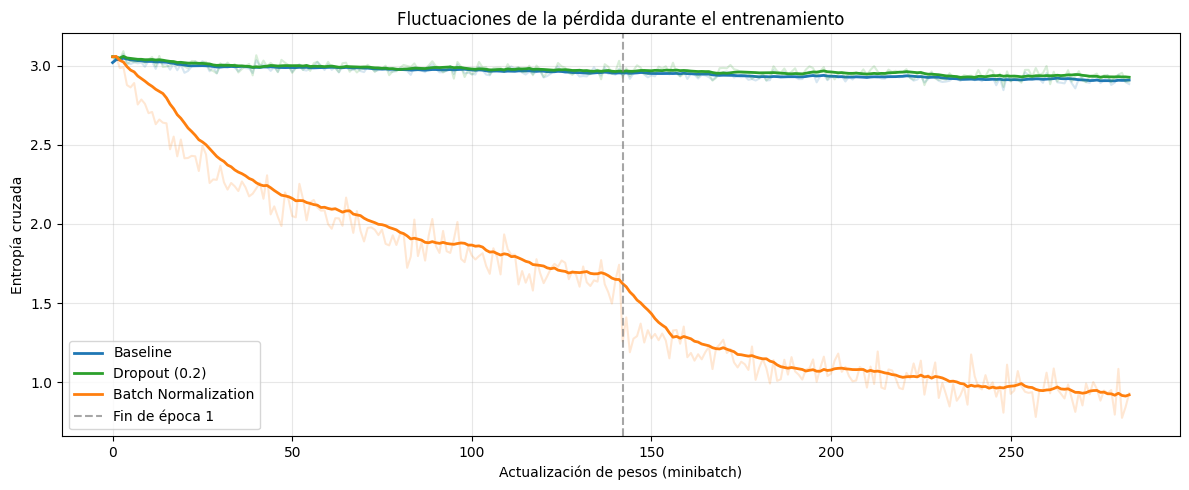

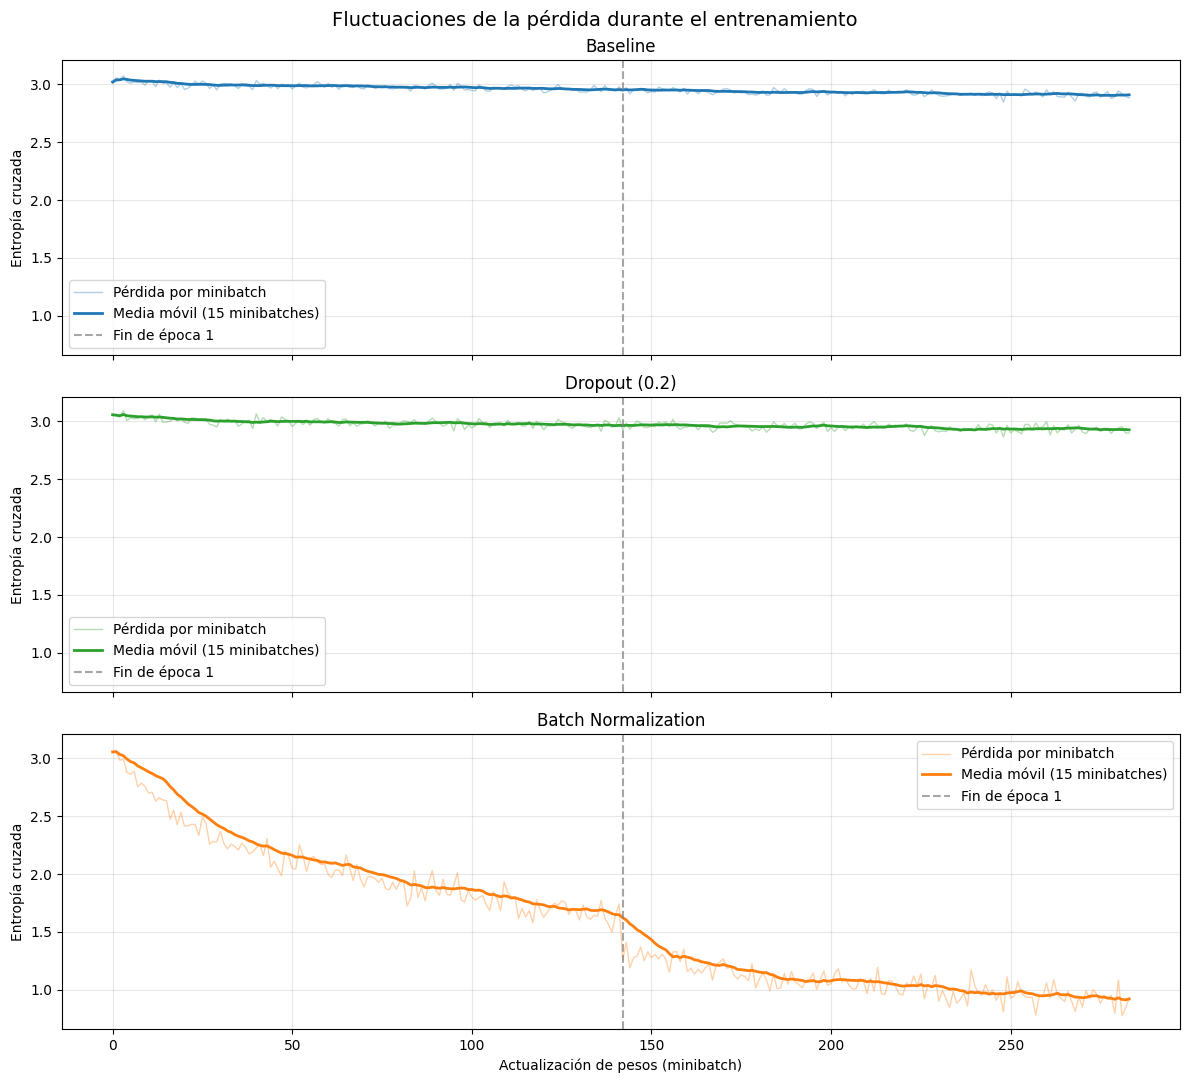

,Modelo,Época,Pérdida promedio,Desv. estándar de fluctuaciones
0,Baseline,1,2.9805,0.0195
1,Baseline,2,2.9253,0.0188
2,Dropout (0.2),1,2.9905,0.0247
3,Dropout (0.2),2,2.9463,0.0259
4,Batch Normalization,1,2.0590,0.0700
5,Batch Normalization,2,1.0599,0.0705


In [42]:
fig, ax = plt.subplots(figsize=(12, 5))

colores = {
    "Baseline": "tab:blue",
    "Dropout (0.2)": "tab:green",
    "Batch Normalization": "tab:orange"
}

VENTANA = 15

for nombre, df in historial_ruido.items():

    color = colores[nombre]

    # Pérdida por minibatch
    ax.plot(
        df["step"],
        df["loss"],
        color=color,
        alpha=0.18
    )

    # Tendencia suavizada
    media_movil = df["loss"].rolling(
        window=VENTANA,
        min_periods=1
    ).mean()

    ax.plot(
        df["step"],
        media_movil,
        color=color,
        linewidth=2,
        label=nombre
    )

# Separación entre épocas
df_referencia = historial_ruido["Baseline"]
n_batches = (df_referencia["epoch"] == 1).sum()

ax.axvline(
    n_batches,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Fin de época 1"
)

ax.set_title("Fluctuaciones de la pérdida durante el entrenamiento")
ax.set_xlabel("Actualización de pesos (minibatch)")
ax.set_ylabel("Entropía cruzada")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Gráficos individuales de fluctuaciones por minibatch

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 11),
    sharex=True,
    sharey=True
)

VENTANA = 15

for ax, (nombre, df) in zip(axes, historial_ruido.items()):

    color = colores[nombre]

    # Pérdida real de cada minibatch
    ax.plot(
        df["step"],
        df["loss"],
        color=color,
        alpha=0.35,
        linewidth=1,
        label="Pérdida por minibatch"
    )

    # Media móvil
    media_movil = df["loss"].rolling(
        window=VENTANA,
        min_periods=1
    ).mean()

    ax.plot(
        df["step"],
        media_movil,
        color=color,
        linewidth=2,
        label=f"Media móvil ({VENTANA} minibatches)"
    )

    # Separación entre épocas
    n_batches = (df["epoch"] == 1).sum()

    ax.axvline(
        n_batches,
        color="gray",
        linestyle="--",
        alpha=0.7,
        label="Fin de época 1"
    )

    ax.set_title(nombre)
    ax.set_ylabel("Entropía cruzada")
    ax.grid(alpha=0.3)
    ax.legend(loc="best")

axes[-1].set_xlabel("Actualización de pesos (minibatch)")

fig.suptitle(
    "Fluctuaciones de la pérdida durante el entrenamiento",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Tabla
resultados_ruido = []

for nombre, df in historial_ruido.items():

    # Media móvil centrada, calculada por época
    tendencia = df.groupby("epoch")["loss"].transform(
        lambda x: x.rolling(
            window=15,
            center=True,
            min_periods=1
        ).mean()
    )

    residuos = df["loss"] - tendencia

    for epoch in sorted(df["epoch"].unique()):

        mask = df["epoch"] == epoch

        resultados_ruido.append({
            "Modelo": nombre,
            "Época": epoch,
            "Pérdida promedio": df.loc[mask, "loss"].mean(),
            "Desv. estándar de fluctuaciones": residuos[mask].std()
        })

df_ruido = pd.DataFrame(resultados_ruido)

display(df_ruido.round(4))

Durante las primeras dos épocas, Batch Normalization presentó una disminución de la pérdida mucho más rápida que el baseline y Dropout. Esto puede relacionarse con la normalización de las entradas de la función Sigmoid, que favorece el proceso de optimización. En cambio, el baseline y Dropout mostraron una reducción más gradual de la pérdida.

Además de esta tendencia general, se observaron pequeñas subidas y bajadas en las curvas, correspondientes a las fluctuaciones de la pérdida entre minibatches. Estas variaciones se producen porque cada minibatch contiene muestras diferentes y, en técnicas como Dropout y Batch Normalization, también intervienen mecanismos que modifican el comportamiento de la red durante el entrenamiento.

Para comparar estas fluctuaciones, se calculó la desviación estándar de la pérdida respecto de una media móvil de 15 minibatches. El baseline presentó la menor variabilidad, con valores cercanos a 0,019 en ambas épocas. Dropout mostró fluctuaciones ligeramente mayores, con desviaciones estándar entre 0,025 y 0,026, lo que es consistente con la desactivación aleatoria de neuronas durante el entrenamiento.

Por su parte, Batch Normalization presentó mayores fluctuaciones en la pérdida durante el entrenamiento. Esto puede relacionarse con que la técnica calcula la media y la varianza de las activaciones para cada minibatch. Como estas estadísticas cambian según las muestras utilizadas, también varía la normalización aplicada a las activaciones.